# IND320 — Project Part 4

- **By:** Agop Haroun
- **GitHub repository:** [G0KU-DOTCOM/Streamlit_dashboard](https://github.com/G0KU-DOTCOM/Streamlit_dashboard)
- **Streamlit application:** [ind320dashboard.streamlit.app](https://ind320dashboard.streamlit.app)

### AI usage

Codex helped identify and verify the overlapping test period, implement and test the exchange rate downloader, collect the NO3 source samples, check timestamp conventions, and build and validate the weekly NO3 dataset. It also helped validate the weather sample and implement the lagged correlation. For forecasting, Codex followed the IND320 SNARIMAX example and used the training period and first model orders approved by the author. It also helped compare the first forecast with two simple baselines and test the seasonal terms separately. It helped run the four chronological backtests using the approved 104-week training length and 4-, 8- and 12-week horizons. For the weather experiment, the author approved a scenario based on past averages for the corresponding ISO weeks. It also helped compare 104 and 156 training weeks with zero or first differencing while retaining the earlier forecast cutoffs. It helped evaluate the fixed candidate settings on the approved January–March 2026 period. It helped perform a predefined SNARIMAX order search on 2025 cutoffs and compare the selected settings on 2026 periods. It helped compare the selected orders with and without precipitation while keeping the approved weather scenario fixed.

Codex also helped prepare the blue Streamlit design sketch and document the proposed navigation and shared versus local controls in section 4.

## 1. Data preparation

### 1.1 Choose the test region and period

Use **NO3** from **14 October through 29 December 2024**. The project includes hourly ERA5 weather for NO3 throughout 2024. The ENTSO-E snapshot includes the NO3–SE2 connection from 11 October 2024. The chosen period starts with the first complete Monday–Sunday week in the overlap and ends on the last Sunday covered by the 2024 weather file. The local NVE history cache contains one NO3 observation for each week (ISO weeks 42–52), and the local ENTSO-E archive contains 1,849 distinct NO3–SE2 hours in the period.

The period includes the switch to winter time on 27 October and the Christmas holidays. These give us specific dates to inspect when we compare hourly timestamps and currency publication dates. The 11 weeks are a test window for combining the data.

The cell below checks that the selected dates fit inside both existing hourly data ranges. The [weather file](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) provides the weather timestamps and the [snapshot plan](../entsoe_plan.json) provides ENTSO-E coverage.

In [1]:
import json
from datetime import date, datetime, time, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd

# The notebook can run from the project root or the notebooks folder.
project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent

region = 'NO3'
nve_area_type, nve_area_number = 'EL', 3
entsoe_connection = 'NO3-SE2'
test_start = date(2024, 10, 14)
test_last_date = date(2024, 12, 29)
test_end = test_last_date + timedelta(days=1)
assert test_start.weekday() == test_end.weekday() == 0, 'Use whole calendar weeks.'

# Express the chosen local date boundaries as instants to check source coverage.
oslo = ZoneInfo('Europe/Oslo')
window_start = datetime.combine(test_start, time.min, tzinfo=oslo)
window_end = datetime.combine(test_end, time.min, tzinfo=oslo)

with (project_root / 'entsoe_plan.json').open() as f:
    entsoe_plan = json.load(f)
entsoe_start = datetime.fromisoformat(entsoe_plan['period']['start_inclusive'])
entsoe_end = datetime.fromisoformat(entsoe_plan['period']['end_exclusive'])
assert entsoe_start <= window_start < window_end <= entsoe_end
assert any(item['connection'] == entsoe_connection for item in entsoe_plan['connections'])

weather_file = project_root / 'data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz'
weather_times = pd.read_csv(weather_file, usecols=['time'], parse_dates=['time'])['time']
assert weather_times.min() <= window_start < window_end <= weather_times.max()

week_count = (test_end - test_start).days // 7
print(f'{region} | {test_start:%d %b} to {test_last_date:%d %b %Y} | {week_count} full weeks')
print(f'Inside the saved weather period and the {entsoe_connection} snapshot period.')

NO3 | 14 Oct to 29 Dec 2024 | 11 full weeks
Inside the saved weather period and the NO3-SE2 snapshot period.


### 1.2 Download EUR and USD exchange rates

The [Norges Bank API](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/) provides daily EUR/NOK and USD/NOK spot rates. The shared [downloader](../dashboard/exchange_rates.py) requests both series in one call. It checks the currency, units, dates and duplicates, then returns one row per observed date with NOK per euro and NOK per US dollar. The dates are calendar dates from the API.

Use the test period from section 1.1 to verify the download. The Christmas-week table includes all seven dates so the dates with no published rate are visible.

In [2]:
import sys

# Make the project's shared module available when Jupyter starts in notebooks/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from dashboard.exchange_rates import download_exchange_rates

# The downloader accepts inclusive dates and keeps the original quote dates.
exchange_rates = download_exchange_rates(test_start, test_last_date)
print(f"Published observations: {exchange_rates['eur_nok'].count()} EUR and "
      f"{exchange_rates['usd_nok'].count()} USD")
exchange_rates.head()

Published observations: 52 EUR and 52 USD


,eur_nok,usd_nok
date,,
2024-10-14,11.7465,10.7618
2024-10-15,11.7660,10.7915
2024-10-16,11.8015,10.8300
2024-10-17,11.8735,10.9272
2024-10-18,11.8115,10.8892


In [3]:
# Add calendar dates to this display only so missing quotes stay visible.
christmas_days = pd.date_range('2024-12-23', '2024-12-29', name='date')
exchange_rates.reindex(christmas_days)

,eur_nok,usd_nok
date,,
2024-12-23,11.8070,11.3605
2024-12-24,NaN,NaN
2024-12-25,NaN,NaN
2024-12-26,NaN,NaN
2024-12-27,11.8435,11.3498
2024-12-28,NaN,NaN
2024-12-29,NaN,NaN


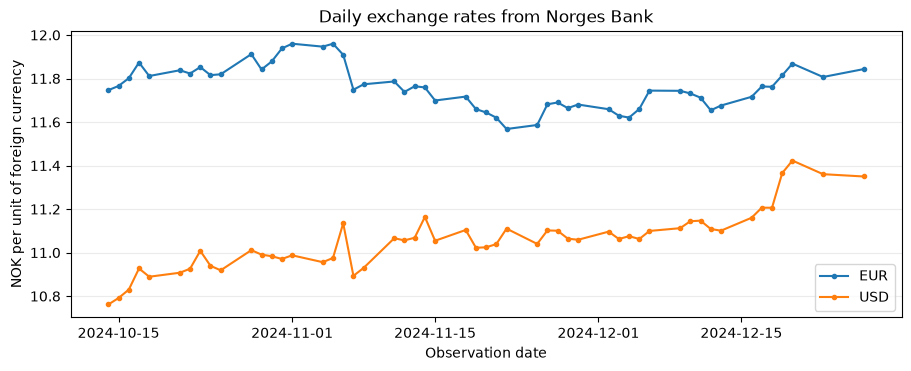

In [4]:
import matplotlib.pyplot as plt

# Mark the observation dates so published quotes are visible on the plot.
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
ax.plot(exchange_rates.index, exchange_rates['eur_nok'], marker='.', label='EUR')
ax.plot(exchange_rates.index, exchange_rates['usd_nok'], marker='.', label='USD')
ax.set(title='Daily exchange rates from Norges Bank', xlabel='Observation date',
       ylabel='NOK per unit of foreign currency')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

In the week of 23–29 December 2024, both series have quotes on 23 and 27 December. The weekly dataset will use the actual quote dates when it counts valid observations and aggregates the rates.

### 1.3 Load the NO3 source samples

Use the test period from section 1.1 for all three sources. Keep the NVE dates and the hourly timestamps from the source readers for inspection in the time-alignment section.

#### NVE Magasinstatistikk

Fetch NVE's public history with the [existing API reader](../dashboard/load_data.py) and select the NO3 price area. Keep the API's ISO year, ISO week, observation date and next-publication field alongside the filling measurements.

In [5]:
from dashboard.load_data import MAX_HISTORY_BYTES, fetch_json, prepare_history

# Keep the raw API response available for inspecting the original date fields.
nve_records, _ = fetch_json('HentOffentligData', MAX_HISTORY_BYTES)
nve_history = prepare_history(nve_records)
nve_selection = (
    nve_history['area_type'].eq(nve_area_type)
    & nve_history['area_number'].eq(nve_area_number)
    & nve_history['observation_date'].between(pd.Timestamp(test_start), pd.Timestamp(test_end), inclusive='left')
)
nve_weekly = nve_history.loc[nve_selection, [
    'observation_date', 'iso_year', 'iso_week', 'filling_fraction',
    'weekly_filling_change', 'next_publication_date',
]].reset_index(drop=True)
print(f'NVE returned {len(nve_weekly)} weekly observations for {region}.')
nve_weekly.head(3)

NVE returned 11 weekly observations for NO3.


,observation_date,iso_year,iso_week,filling_fraction,weekly_filling_change,next_publication_date
0,2024-10-20,2024,42,0.870708,0.004746,2024-10-30 13:00:00
1,2024-10-27,2024,43,0.905651,0.034929,2024-11-06 13:00:00
2,2024-11-03,2024,44,0.923453,0.017802,2024-11-13 13:00:00


#### Open-Meteo ERA5

Reuse the [saved NO3 hourly summary](../data/weather/NO3_era5_2024-01-01_2024-12-31_hourly.csv.gz) from Part 3. Each record includes the UTC timestamp, regional means for temperature and precipitation, and the number of sampled locations.

In [6]:
from dashboard.weather_data import read_weather_summary

# Validate the saved calendar-year summary before taking the sample.
weather_year = test_start.year
weather_history = read_weather_summary(region, date(weather_year, 1, 1), date(weather_year, 12, 31))
if weather_history is None:
    raise FileNotFoundError(f'The saved ERA5 summary for {region} in {weather_year} is missing.')
weather_selection = weather_history['time'].between(window_start, window_end, inclusive='left')
weather_hourly = weather_history.loc[weather_selection].reset_index(drop=True)
print(f'{len(weather_hourly):,} weather hours for {region}.')
weather_hourly.head(3)

1,849 weather hours for NO3.


,time,temperature_2m,precipitation,point_count
0,2024-10-13 22:00:00+00:00,3.7097,0.6045,1000
1,2024-10-13 23:00:00+00:00,3.5154,0.5293,1000
2,2024-10-14 00:00:00+00:00,3.3849,0.4395,1000


#### ENTSO-E transfers in MongoDB

Use the app's [read-only query](../dashboard/transfers.py) to load the saved 2024 data for NO3–SE2, then select the test period. A complete hour has a full 60 minutes of coverage and a valid energy value in each direction. The MongoDB connection reads the URI from the local `.streamlit/secrets.toml` file.

In [7]:
from dashboard.transfers import COLLECTION, DATABASE, complete_hours, read_year
from pipeline.entsoe_mongo import connect

# Use the existing MongoDB connection and bounded query for a single border and year.
with connect(project_root) as client:
    entsoe_history = read_year(client[DATABASE][COLLECTION], entsoe_connection, test_start.year)
entsoe_selection = (entsoe_history.index >= window_start) & (entsoe_history.index < window_end)
entsoe_hourly = entsoe_history.loc[entsoe_selection].copy()
complete = complete_hours(entsoe_hourly).sum()
print(f'{entsoe_connection} has {complete:,} of {len(entsoe_hourly):,} complete hours in the test period.')
entsoe_hourly.head(3)

NO3-SE2 has 1,849 of 1,849 complete hours in the test period.


,import_mwh,export_mwh,import_coverage_minutes,export_coverage_minutes
time_utc,,,,
2024-10-13 22:00:00+00:00,0.0,50.61,60.0,60.0
2024-10-13 23:00:00+00:00,0.0,69.85,60.0,60.0
2024-10-14 00:00:00+00:00,0.0,55.95,60.0,60.0


### 1.4 Investigate time zones and publication dates

| Source | Example from the project data | What the time represents |
| --- | --- | --- |
| NVE Magasinstatistikk | `dato_Id` is `2024-10-27`, ISO week 43 | Norwegian Sunday date. The reference is the end of Sunday (Monday 00:00). NVE can use an earlier measurement if the reference-time measurement is unavailable. |
| ENTSO-E | `time_utc` is `2024-10-13 22:00Z` in MongoDB | UTC start of the hour whose import and export energy are stored in MWh. This is Monday 14 October at 00:00 in Oslo. |
| Open-Meteo ERA5 | `time` is `2024-10-13 22:00Z` in the saved data | We requested GMT. Temperature is at the timestamp. Precipitation is the total for the hour ending at that timestamp. |
| Norges Bank | `TIME_PERIOD` is `2024-12-23` | Calendar date of the EUR and USD quotes. The CSV row contains a date with no time of day or offset. |

[NVE handbook](https://webfileservice.nve.no/API/PublishedFiles/Download/64edbe40-b965-4c90-a114-88162ffff454/201903383/3435075) · [ENTSO-E response times](https://transparencyplatform.zendesk.com/hc/en-us/articles/12786431986964-Response-Time-Zone) · [Hourly transfer processing](../pipeline/entsoe_hourly.py) · [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) · [Norges Bank API guide](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/)

#### When the values become available

- **NVE.** The usual release is Wednesday at 13:00 Norwegian time. The week 43 API row points to **6 November** in `neste_Publiseringsdato`. The previous row points to **30 October at 13:00**. NVE's week 43 article is dated 29 October and was updated on 30 October. This gives us a scheduled release and article dates. The exact first API availability is unknown. At year-end, NVE explicitly scheduled week 52 for **2 January 2025 at 13:00** and its report is dated 2 January. We keep that release separate from the observation date of 29 December 2024. [Week 43 report](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-43-2024/) · [Week 52 announcement](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-51-2024/) · [Week 52 report](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/vassmagasinstatistikk-veke-52-2024/)
- **ENTSO-E.** The MongoDB snapshot keeps measurement hours and coverage. It has no publication or revision timestamps per hour. [Transfer data layout](../entsoe_plan.json)
- **Open-Meteo.** The documented ERA5 archive delay is about five days. A full week of ERA5 can therefore be unavailable when the NVE value for that week is published. [Open-Meteo dataset availability](https://open-meteo.com/en/docs/historical-weather-api#data-sources)
- **Norges Bank.** The bank lists approximate publication at 16:00 CET on business days. We retain the quote date and leave days without a quote missing. The Christmas example in section 1.2 shows only two quote dates, 23 and 27 December. [Norges Bank FAQ](https://www.norges-bank.no/en/topics/statistics/exchange_rates/valutakursar-faq/)

#### Check the autumn clock change

Keep hourly timestamps in UTC and define the week as Monday 00:00 up to the next Monday 00:00 in `Europe/Oslo`. For precipitation, use the start of its one-hour interval, one hour before its reported timestamp. Keep the original weather timestamps for reference. The sample below checks complete hourly coverage against an independently generated UTC grid for NVE week 43.

In [8]:
# Convert both local week boundaries to UTC before building the hourly grid.
clock_week_start = pd.Timestamp('2024-10-21', tz=oslo).tz_convert('UTC')
clock_week_end = pd.Timestamp('2024-10-28', tz=oslo).tz_convert('UTC')
expected_hours = pd.date_range(clock_week_start, clock_week_end, freq='h', inclusive='left')

# The full weather file also contains the report for the final precipitation hour.
weather_utc = pd.DatetimeIndex(weather_history['time'])
one_hour = pd.Timedelta(hours=1)
precipitation_start_utc = weather_utc - one_hour
clock_temperature = weather_utc[(weather_utc >= clock_week_start) & (weather_utc < clock_week_end)]
clock_precipitation = precipitation_start_utc[
    (precipitation_start_utc >= clock_week_start) & (precipitation_start_utc < clock_week_end)
]
clock_transfers = entsoe_hourly.loc[
    (entsoe_hourly.index >= clock_week_start) & (entsoe_hourly.index < clock_week_end)
]

assert len(expected_hours) == 169
assert clock_temperature.equals(expected_hours) and clock_precipitation.equals(expected_hours)
assert clock_transfers.index.equals(expected_hours) and complete_hours(clock_transfers).all()
print('Week 43: 169 hours each for temperature, precipitation and complete transfers.')

# Both occurrences of 02:00 are valid hours and have different UTC offsets.
local_hours = expected_hours.tz_convert(oslo)
repeated_hour = local_hours[local_hours.strftime('%Y-%m-%d %H:%M') == '2024-10-27 02:00']
assert len(repeated_hour) == 2 and repeated_hour.is_unique
pd.DataFrame({'UTC': repeated_hour.tz_convert('UTC'), 'Europe/Oslo': repeated_hour})

Week 43: 169 hours each for temperature, precipitation and complete transfers.


,UTC,Europe/Oslo
0,2024-10-27 00:00:00+00:00,2024-10-27 02:00:00+02:00
1,2024-10-27 01:00:00+00:00,2024-10-27 02:00:00+01:00


#### Check midnight and the ISO year boundary

A temperature reading or transfer hour at Monday 00:00 belongs to the new week. The precipitation reported at that same time belongs to the Sunday hour just ended. On 30 December 2024 the new week is ISO week **2025-W01**, even though the calendar date is in 2024. Use ISO year together with ISO week when matching weekly data.

In [9]:
def oslo_iso_week(timestamps):
    # ISO year can differ from calendar year around New Year.
    iso = timestamps.tz_convert(oslo).isocalendar()
    return [f'{year}-W{week:02d}' for year, week in zip(iso['year'], iso['week'])]

# Match the NVE labels to their date fields before using them as week keys.
nve_iso = nve_weekly['observation_date'].dt.isocalendar()
assert nve_iso['year'].eq(nve_weekly['iso_year']).all()
assert nve_iso['week'].eq(nve_weekly['iso_week']).all()

boundary_times = pd.to_datetime([window_start, clock_week_end, window_end], utc=True)
assert boundary_times.isin(weather_utc).all()
temperature_and_transfer_weeks = oslo_iso_week(boundary_times)
precipitation_weeks = oslo_iso_week(boundary_times - one_hour)
assert temperature_and_transfer_weeks == ['2024-W42', '2024-W44', '2025-W01']
assert precipitation_weeks == ['2024-W41', '2024-W43', '2024-W52']

pd.DataFrame({
    'Local boundary': boundary_times.tz_convert(oslo),
    'Temperature / transfer week': temperature_and_transfer_weeks,
    'Precipitation week': precipitation_weeks,
})

,Local boundary,Temperature / transfer week,Precipitation week
0,2024-10-14 00:00:00+02:00,2024-W42,2024-W41
1,2024-10-28 00:00:00+01:00,2024-W44,2024-W43
2,2024-12-30 00:00:00+01:00,2025-W01,2024-W52


#### Rules for the weekly dataset

Use NVE's ISO year and week for filling and Oslo calendar weeks for the other sources. Use the start of each hourly interval for ENTSO-E and precipitation, the observed hour for temperature, and the calendar quote date for exchange rates. Determine expected coverage from the actual local week boundaries. For forecasting, separately check which observations could have been available at each cutoff. The historical samples support alignment by observation time. Recreating exact past release times requires publication history.

### 1.5 Build the weekly NO3 dataset

Keep one NVE filling observation per ISO year and week as the target. For each week, average the hourly temperatures, sum the hourly precipitation and transfer energy, and average each exchange rate over its observed quote days. Filling is a fraction (0.90 means 90%), precipitation is in mm, and transfer energy is in MWh for NO3–SE2.

Count the available hours for each hourly variable. Leave its weekly value missing if any expected hour is missing. For the currencies, count the dates with a quote for each series and check whether both series have a value for every returned date. Holiday weeks can have fewer quote days.

In [10]:
week_columns = ['iso_year', 'iso_week']


def group_by_iso_week(frame, calendar_dates):
    # Use Oslo timestamps for hourly sources and calendar dates for exchange rates.
    iso = calendar_dates.isocalendar()
    year = pd.Index(iso['year'], name='iso_year')
    week = pd.Index(iso['week'], name='iso_week')
    return frame.groupby([year, week])


# The grid uses UTC intervals between the two Oslo boundaries and includes both 02:00 hours.
hour_grid = pd.date_range(
    pd.Timestamp(window_start).tz_convert('UTC'), pd.Timestamp(window_end).tz_convert('UTC'),
    freq='h', inclusive='left', name='time_utc',
)
temperature = weather_hourly.set_index('time')['temperature_2m']
# Use the full weather file for precipitation reported at the final midnight.
precipitation = weather_history.set_index(precipitation_start_utc)['precipitation']
hourly_inputs = pd.DataFrame({
    'temperature_c': temperature,
    'precipitation_mm': precipitation,
    'import_mwh': entsoe_hourly['import_mwh'],
    'export_mwh': entsoe_hourly['export_mwh'],
}, index=hour_grid)

# The transfer reader already leaves partly covered hours missing by direction.
hourly_groups = group_by_iso_week(hourly_inputs, hour_grid.tz_convert(oslo))
expected_week_hours = hourly_groups.size().rename('expected_hours')
hour_counts = hourly_groups.count()
complete_by_variable = hour_counts.eq(expected_week_hours, axis=0)

temperature_weekly = hourly_groups['temperature_c'].mean().to_frame()
totals_weekly = hourly_groups[['precipitation_mm', 'import_mwh', 'export_mwh']].sum(min_count=1)
# Only publish a weekly statistic when the variable covers the entire week.
hourly_weekly = temperature_weekly.join(totals_weekly).where(complete_by_variable)
hourly_weekly = hourly_weekly.join(expected_week_hours).join(hour_counts.rename(columns={
    'temperature_c': 'temperature_hours', 'precipitation_mm': 'precipitation_hours',
    'import_mwh': 'import_hours', 'export_mwh': 'export_hours',
}))
hourly_weekly['hourly_complete'] = complete_by_variable.all(axis=1)

In [11]:
# Group the published quote dates directly by ISO year and week.
quote_groups = group_by_iso_week(exchange_rates, exchange_rates.index)
quote_counts = quote_groups.count()
quote_dates = quote_groups.size().rename('fx_quote_days')
fx_weekly = quote_groups.mean().join(quote_dates).join(quote_counts.rename(columns={
    'eur_nok': 'eur_quote_days', 'usd_nok': 'usd_quote_days',
}))
fx_weekly['both_rates_each_quote_day'] = quote_counts.eq(quote_dates, axis=0).all(axis=1)

# A left join keeps every NVE observation even if a predictor week is absent.
weekly_no3 = nve_weekly.join(hourly_weekly, on=week_columns, validate='one_to_one')
weekly_no3 = weekly_no3.join(fx_weekly, on=week_columns, validate='one_to_one')
fx_count_columns = ['fx_quote_days', 'eur_quote_days', 'usd_quote_days']
weekly_no3[fx_count_columns] = weekly_no3[fx_count_columns].fillna(0).astype(int)
weekly_no3['both_rates_each_quote_day'] = weekly_no3['both_rates_each_quote_day'].eq(True)

# Round for display. Retain full precision in weekly_no3.
value_columns = ['filling_fraction', 'temperature_c', 'precipitation_mm', 'import_mwh', 'export_mwh', 'eur_nok', 'usd_nok']
weekly_no3.set_index(week_columns)[value_columns].round(3)

filling_fraction  temperature_c  precipitation_mm  \
iso_year iso_week                                                      
2024     42                   0.871          7.441            18.993   
         43                   0.906          7.536            79.830   
         44                   0.923          3.189            99.562   
         45                   0.933          5.174            13.153   
         46                   0.940          4.554            71.253   
         47                   0.919         -3.425            34.104   
         48                   0.907          1.533            54.885   
         49                   0.893         -0.488            19.901   
         50                   0.864          0.772            61.222   
         51                   0.847          0.251            60.503   
         52                   0.861          2.450            76.867   

                   import_mwh  export_mwh  eur_nok  usd_nok  
iso_year iso_week                                            
2024     42         80820.805     2588.87   11.800   10.840  
         43         79247.128     3903.51   11.830   10.940  
         44         54783.078     5535.35   11.906   10.989  
         45         26034.152    14999.03   11.868   10.978  
         46         16794.570    22078.93   11.750   11.082  
         47         45894.558    18947.59   11.642   11.060  
         48         47995.365    10343.99   11.660   11.073  
         49         25544.628    14669.76   11.663   11.079  
         50         27970.550    25226.46   11.703   11.123  
         51         48595.315    24524.65   11.785   11.272  
         52         60526.730    18650.22   11.825   11.355

In [12]:
# Show the row counts used for the weekly statistics.
coverage_columns = [
    'expected_hours', 'temperature_hours', 'precipitation_hours', 'import_hours', 'export_hours',
    'hourly_complete', 'eur_quote_days', 'usd_quote_days', 'both_rates_each_quote_day',
]
weekly_no3.set_index(week_columns)[coverage_columns]

expected_hours  temperature_hours  precipitation_hours  \
iso_year iso_week                                                           
2024     42                   168                168                  168   
         43                   169                169                  169   
         44                   168                168                  168   
         45                   168                168                  168   
         46                   168                168                  168   
         47                   168                168                  168   
         48                   168                168                  168   
         49                   168                168                  168   
         50                   168                168                  168   
         51                   168                168                  168   
         52                   168                168                  168   

                   import_hours  export_hours  hourly_complete  \
iso_year iso_week                                                
2024     42                 168           168             True   
         43                 169           169             True   
         44                 168           168             True   
         45                 168           168             True   
         46                 168           168             True   
         47                 168           168             True   
         48                 168           168             True   
         49                 168           168             True   
         50                 168           168             True   
         51                 168           168             True   
         52                 168           168             True   

                   eur_quote_days  usd_quote_days  both_rates_each_quote_day  
iso_year iso_week                                                             
2024     42                     5               5                       True  
         43                     5               5                       True  
         44                     5               5                       True  
         45                     5               5                       True  
         46                     5               5                       True  
         47                     5               5                       True  
         48                     5               5                       True  
         49                     5               5                       True  
         50                     5               5                       True  
         51                     5               5                       True  
         52                     2               2                       True

### 1.6 Check data quality and available history

Verify the weekly join before using it in the analyses. Then count available weeks and the longest consecutive run for each combination of data sources. In the report below, dates span the Monday of the first week to the Sunday of the last week in the run.

In [13]:
# The joined rows must match the expected test weeks and retain the original NVE target.
test_weeks = pd.MultiIndex.from_frame(weekly_no3[week_columns])
assert test_weeks.is_unique and list(test_weeks) == list(expected_week_hours.index)
assert weekly_no3['filling_fraction'].equals(nve_weekly['filling_fraction'])

for measure, count in zip(
    ['temperature_c', 'precipitation_mm', 'import_mwh', 'export_mwh'],
    ['temperature_hours', 'precipitation_hours', 'import_hours', 'export_hours'],
):
    assert weekly_no3[count].between(0, weekly_no3['expected_hours']).all()
    # A missing hour leaves that variable's weekly statistic missing.
    assert weekly_no3[measure].notna().eq(weekly_no3[count].eq(weekly_no3['expected_hours'])).all()

coverage = weekly_no3.set_index(week_columns)
assert coverage.loc[(2024, 43), 'expected_hours'] == 169
assert coverage.loc[(2024, 52), ['eur_quote_days', 'usd_quote_days']].eq(2).all()
assert weekly_no3[['eur_quote_days', 'usd_quote_days']].sum().to_list() == exchange_rates.count().to_list()
print(f'{len(test_weeks)} unique weeks with their original NVE filling values.')
print(f"{weekly_no3['hourly_complete'].sum()} weeks with full weather and transfer coverage.")
print('Week 43 has 169 expected hours. Week 52 has two quote dates per currency.')

11 unique weeks with their original NVE filling values.
11 weeks with full weather and transfer coverage.
Week 43 has 169 expected hours. Week 52 has two quote dates per currency.


In [14]:
# Use the full NVE history and saved ERA5 file to measure coverage beyond the test period.
no3_history = nve_history.loc[
    nve_history['area_type'].eq(nve_area_type) & nve_history['area_number'].eq(nve_area_number)
].copy()
nve_weeks = pd.MultiIndex.from_frame(no3_history.loc[no3_history['filling_fraction'].notna(), week_columns])
assert nve_weeks.is_unique

def weekly_weather(hourly_weather):
    # Use UTC hour starts for alignment, and Oslo Mondays for the reporting weeks.
    hourly = hourly_weather.set_index('time')
    precipitation_starts = hourly.index - one_hour
    first_day = precipitation_starts[0].tz_convert(oslo).normalize()
    last_day = hourly.index[-1].tz_convert(oslo).normalize()
    first_monday = first_day - pd.DateOffset(days=first_day.weekday())
    last_boundary = last_day + pd.DateOffset(days=7 - last_day.weekday())
    grid = pd.date_range(first_monday.tz_convert('UTC'), last_boundary.tz_convert('UTC'),
                         freq='h', inclusive='left')

    # A precipitation record describes the preceding hour. Use its interval start.
    weather_inputs = pd.DataFrame({
        'temperature_c': hourly['temperature_2m'],
        'precipitation_mm': hourly['precipitation'].set_axis(precipitation_starts),
    }, index=grid)
    groups = group_by_iso_week(weather_inputs, grid.tz_convert(oslo))
    complete = groups.count().eq(groups.size(), axis=0)
    weekly = groups['temperature_c'].mean().to_frame().join(
        groups['precipitation_mm'].sum(min_count=1)
    )
    return weekly.where(complete)


weather_weekly_2024 = weekly_weather(weather_history)
nve_weather_weeks = nve_weeks.intersection(weather_weekly_2024.dropna().index)

# Full overlap uses the assembled test weeks with complete hourly data and paired FX quotes.
verified_overlap = weekly_no3['hourly_complete'] & weekly_no3['both_rates_each_quote_day']
all_sources_weeks = test_weeks[verified_overlap]


def coverage_summary(week_keys):
    # ISO Mondays are spaced by exactly seven calendar days in a consecutive run.
    starts = pd.Series(pd.to_datetime([date.fromisocalendar(year, week, 1) for year, week in week_keys]))
    if starts.empty:
        return {'Weeks': 0, 'Longest run': 0, 'From': None, 'Through': None}
    starts = starts.sort_values(ignore_index=True)
    run_number = starts.diff().ne(pd.Timedelta(days=7)).cumsum()
    runs = starts.groupby(run_number).agg(['size', 'min', 'max'])
    longest = runs.loc[runs['size'].idxmax()]
    return {
        'Weeks': len(starts),
        'Longest run': int(longest['size']),
        'From': longest['min'].date(),
        'Through': (longest['max'] + pd.Timedelta(days=6)).date(),
    }


coverage_report = pd.DataFrame.from_dict({
    'NVE filling': coverage_summary(nve_weeks),
    'NVE filling and complete 2024 weather': coverage_summary(nve_weather_weeks),
    'All four sources in the verified overlap': coverage_summary(all_sources_weeks),
}, orient='index').rename_axis('Data available for NO3')
coverage_report

,Weeks,Longest run,From,Through
Data available for NO3,,,,
NVE filling,1663,1663,1995-01-02,2026-11-15
NVE filling and complete 2024 weather,51,51,2024-01-08,2024-12-29
All four sources in the verified overlap,11,11,2024-10-14,2024-12-29


#### What the coverage allows

The saved weather data cover 2024 in UTC. The first Norwegian week starts an hour before the first temperature record, so complete weather weeks start on 8 January. The NO3–SE2 snapshot starts in October 2024, which brings the verified overlap across all four sources down to the 11 test weeks.

Use the long NVE series for a filling-only forecast benchmark. The saved weather can support the first exploratory lag analysis. The next section extends the NO3 weather series through 2023–2025 for tests across several seasons. An experiment using all four sources needs complete weather and quote coverage within the NO3–SE2 snapshot period. Compare models on the same forecast dates and use the coverage checks above before choosing dates.

## 2. Weather and reservoir filling

### Extend the NO3 weather history

The [three-year ERA5 summary](../data/weather/NO3_era5_2023-2025_hourly_sample100.csv.gz) uses the same 100 sampled NO3 locations in 2023, 2024 and 2025. The smaller sample limits the number of requests. To check how closely it tracks the original 1,000-point series, compare their weekly temperature means and precipitation totals over the 51 complete weeks available in the original 2024 file.

To reproduce the sample, sort the NO3 point IDs from `data/geography/weather_locations.csv` and draw 100 with `Random(320).sample(ids, 100)`. Pass those IDs to `download_weather` with `hourly=True` and `batch_size=50` for each calendar year. The local Part 3 point data provided 2024. The archive provided 2023 and 2025. The saved file contains the hourly regional means and point counts. [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) · [API limits](https://open-meteo.com/en/terms) · [Project downloader](../dashboard/weather_data.py)

In [15]:
forecast_weather_file = project_root / 'data/weather/NO3_era5_2023-2025_hourly_sample100.csv.gz'
forecast_weather = pd.read_csv(forecast_weather_file, parse_dates=['time'])
expected_weather_hours = pd.date_range('2023-01-01', '2026-01-01', freq='h', inclusive='left', tz='UTC')
assert pd.DatetimeIndex(forecast_weather['time']).equals(expected_weather_hours)
assert forecast_weather['point_count'].eq(100).all() and not forecast_weather.isna().any().any()

weather_weekly_3_years = weekly_weather(forecast_weather)
reference_2024 = weather_weekly_2024.dropna()
errors = weather_weekly_3_years.loc[reference_2024.index].sub(reference_2024).abs()
print(f'{len(forecast_weather):,} hours from the same 100 locations in 2023–2025.')
pd.DataFrame({'Mean absolute error': errors.mean(), 'Largest absolute error': errors.max()}).round(2)

26,304 hours from the same 100 locations in 2023–2025.


,Mean absolute error,Largest absolute error
temperature_c,0.14,0.36
precipitation_mm,0.79,3.11


### Sliding-window correlation with weekly filling change

Compare each weather property with NVE's weekly change in NO3 filling. A positive lag of one week pairs a weather value with the following week's filling change. The Pearson correlation uses a trailing window ending on the displayed date. Each estimate requires a full window of valid pairs. [Course chapter on lagged correlation](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/2_ML_approach.ipynb)

In [16]:
def sliding_weather_correlation(weekly, weather_property, lag_weeks, window_weeks):
    # Reinsert gaps so shifting by one position means exactly one calendar week.
    aligned = weekly.sort_index().asfreq('W-SUN')
    lagged_weather = aligned[weather_property].shift(lag_weeks)
    return lagged_weather.rolling(window_weeks).corr(aligned['weekly_filling_change'])


filling_change = no3_history.set_index(week_columns)[['observation_date', 'weekly_filling_change']]
correlation_2024 = reference_2024.join(filling_change, how='inner').set_index('observation_date')
correlation_3_years = weather_weekly_3_years.dropna().join(filling_change, how='inner').set_index('observation_date')
print(f'{len(correlation_2024)} complete weather and reservoir weeks in the 2024 reference.')
print(f'{len(correlation_3_years)} in the extended series.')

settings = [(8, 0), (13, 0), (13, 1), (26, 1)]
properties = {'temperature_c': 'Temperature', 'precipitation_mm': 'Precipitation'}
results = []
for name, weekly, trials in [('2024', correlation_2024, [(13, 1)]),
                             ('2023–2025', correlation_3_years, settings)]:
    for column, label in properties.items():
        for window, lag in trials:
            r = sliding_weather_correlation(weekly, column, lag, window).dropna()
            results.append({
                'Period': name, 'Weather': label, 'Window in weeks': window, 'Lag in weeks': lag,
                'Windows': len(r), 'Lowest r': r.min(), 'Highest r': r.max(),
            })
pd.DataFrame(results).round(2)

51 complete weather and reservoir weeks in the 2024 reference.
156 in the extended series.


,Period,Weather,Window in weeks,Lag in weeks,Windows,Lowest r,Highest r
0,2024,Temperature,13,1,38,-0.49,0.82
1,2024,Precipitation,13,1,38,-0.59,0.03
2,2023–2025,Temperature,8,0,149,-0.85,0.94
3,2023–2025,Temperature,13,0,144,-0.68,0.96
4,2023–2025,Temperature,13,1,143,-0.62,0.85
5,2023–2025,Temperature,26,1,130,-0.31,0.81
6,2023–2025,Precipitation,8,0,149,-0.74,1.00
7,2023–2025,Precipitation,13,0,144,-0.55,0.93
8,2023–2025,Precipitation,13,1,143,-0.73,0.64
9,2023–2025,Precipitation,26,1,130,-0.60,0.48


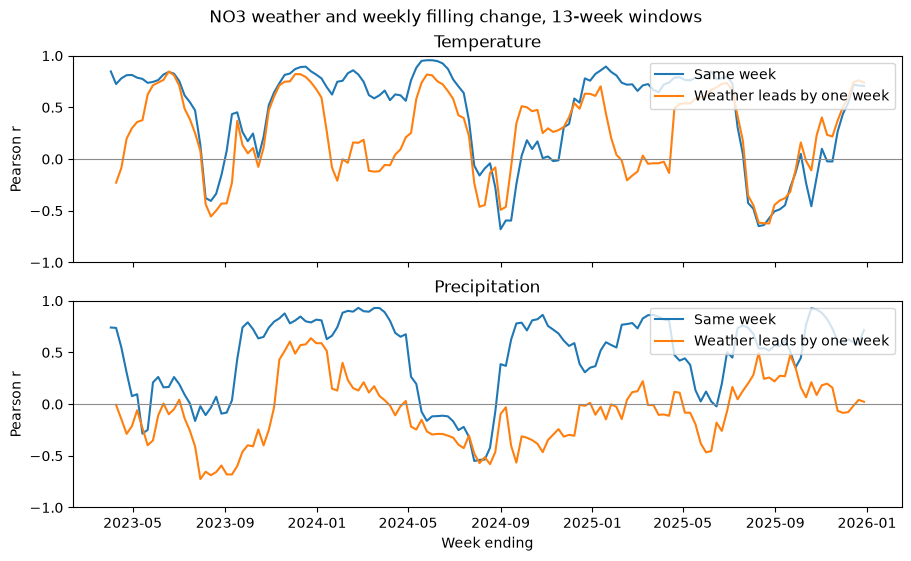

In [17]:
# Compare same-week and one-week leads at a fixed window on the same sample.
window_weeks = 13
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, layout='constrained')
for ax, (column, label) in zip(axes, properties.items()):
    for lag in (0, 1):
        r = sliding_weather_correlation(correlation_3_years, column, lag, window_weeks)
        ax.plot(r.index, r, label='Same week' if lag == 0 else 'Weather leads by one week')
    ax.axhline(0, color='0.55', linewidth=0.8)
    ax.set(title=label, ylabel='Pearson r', ylim=(-1, 1))
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Week ending')
fig.suptitle('NO3 weather and weekly filling change, 13-week windows')
plt.show()

#### Initial correlation findings

In the 13-week same-week comparison, temperature correlation fell from **0.96** in the window ending 2 June 2024 to **−0.68** in the window ending 1 September. With temperature one week ahead, increasing the window from 13 to 26 weeks changed the observed range from about **−0.62 to 0.85** to **−0.31 to 0.81**.

Precipitation also changed sign over time. With a 13-week window, its highest same-week correlation was **0.93**, and the highest one-week lead correlation was **0.64**. The change in sign and the weaker lead correlations make chronological backtesting important. Compare candidate weather inputs with a filling-only model and check when each input would have been available at the forecast date.

## 3. Reservoir forecasting with River SNARIMAX

### 3.1 First filling-only forecast

Follow the learn-one loop in the course's River example. For this first NO3 experiment, use **8 January 2023–5 October 2025** as training, then predict **12 weekly observations**, from **12 October through 28 December 2025**. These dates and the first orders were selected with the author before running the model.

The first course model uses **p=3, d=1, q=3** and River's default scaler and linear regressor. Here p includes three past differenced filling values, d applies first differencing, and q includes three past prediction errors. The seasonal settings initially follow River's defaults, **m=1, sp=0, sd=0, sq=0**. The shared function exposes each order for subsequent experiments. Training and forecasting use filling fractions, so a value of 0.90 means 90%.

The [shared forecast function](../dashboard/forecasting.py) selects one area and training period, checks for missing weeks and invalid values, and trains in chronological order. River generates the 12-step dynamic forecast by feeding predictions back into the model. Observed values from those 12 weeks are used only to evaluate the completed forecast. This is a historical split based on observation dates. Exact historical API release and revision times are unavailable, as described in section 1.4.

[Course River example](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/3_Streaming/2_Streaming_models.ipynb) · [Course explanation of dynamic prediction](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/3_SARIMAX.ipynb) · [River SNARIMAX](https://riverml.xyz/dev/api/time-series/SNARIMAX/)

In [18]:
from time import perf_counter

import numpy as np

from dashboard.forecasting import forecast_reservoir_snarimax

# Keep the approved experiment settings together for reproducibility.
forecast_train_start = '2023-01-08'
forecast_train_end = '2025-10-05'
forecast_horizon = 12
snarimax_orders = dict(p=3, d=1, q=3, m=1, sp=0, sd=0, sq=0)

started = perf_counter()
training_filling, first_forecast = forecast_reservoir_snarimax(
    nve_history, nve_area_type, nve_area_number,
    forecast_train_start, forecast_train_end, forecast_horizon, **snarimax_orders,
)
forecast_runtime = perf_counter() - started
assert len(training_filling) == 144 and len(first_forecast) == 12
assert training_filling.index.max() < first_forecast.index.min()
print(f'Trained on {len(training_filling)} weekly NO3 observations, ending {training_filling.index[-1]:%d %B %Y}.')
print(f'Predicted {len(first_forecast)} weeks in {forecast_runtime:.3f} seconds.')
first_forecast.mul(100).rename('Forecast filling (%)').to_frame().round(2)

Trained on 144 weekly NO3 observations, ending 05 October 2025.
Predicted 12 weeks in 0.004 seconds.


,Forecast filling (%)
observation_date,
2025-10-12,89.19
2025-10-19,88.91
2025-10-26,88.63
2025-11-02,88.39
2025-11-09,88.15
2025-11-16,87.91
2025-11-23,87.68
2025-11-30,87.46
2025-12-07,87.23


In [19]:
# Look up held-out observations only after the forecast has been generated.
observed_filling = no3_history.set_index('observation_date')['filling_fraction']
forecast_comparison = first_forecast.to_frame('snarimax').join(observed_filling.rename('observed'))
assert forecast_comparison['observed'].notna().all()

# Errors in percentage points are 100 times errors in filling fraction.
forecast_errors_pp = 100 * (forecast_comparison['snarimax'] - forecast_comparison['observed'])
first_forecast_scores = pd.Series({
    'Weeks forecast': len(forecast_comparison),
    'MAE (percentage points)': forecast_errors_pp.abs().mean(),
    'RMSE (percentage points)': np.sqrt(forecast_errors_pp.pow(2).mean()),
    'Last-week error (percentage points)': forecast_errors_pp.iloc[-1],
}, name='First NO3 SNARIMAX run')
first_forecast_scores.round(2).to_frame()

,First NO3 SNARIMAX run
Weeks forecast,12.00
MAE (percentage points),5.15
RMSE (percentage points),6.45
Last-week error (percentage points),12.82


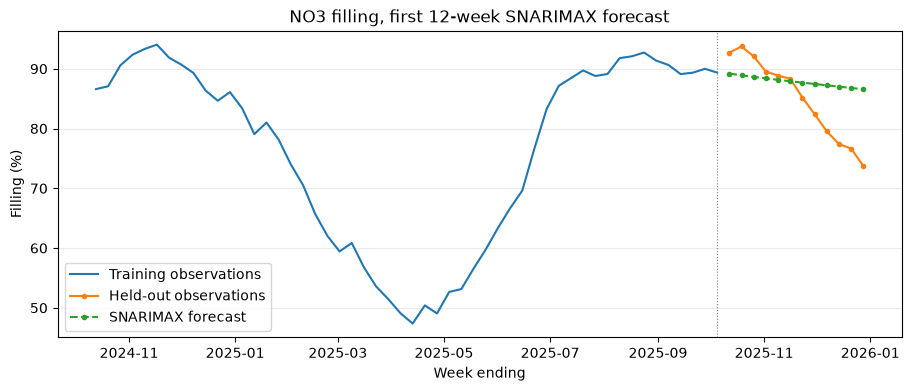

In [20]:
# Show the last year of training alongside the held-out weeks and forecasts.
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
ax.plot(training_filling.tail(52).index, training_filling.tail(52) * 100, label='Training observations')
ax.plot(forecast_comparison.index, forecast_comparison['observed'] * 100,
        marker='.', label='Held-out observations')
ax.plot(first_forecast.index, first_forecast * 100, marker='.', linestyle='--', label='SNARIMAX forecast')
ax.axvline(training_filling.index[-1], color='0.5', linewidth=0.8, linestyle=':')
ax.set(title='NO3 filling, first 12-week SNARIMAX forecast',
       xlabel='Week ending', ylabel='Filling (%)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

#### First-run findings

The initial p=3, d=1, q=3 model achieved a mean absolute error of **5.15 percentage points** and RMSE of **6.45 percentage points** over the 12 held-out weeks. It forecast **86.57%** filling for 28 December 2025, while the observed value was **73.75%**, an overestimate of **12.82 percentage points**. It predicted a gradual decline and underestimated the later fall.

This run demonstrates training on a selected region and period, a recursive multi-week forecast, and evaluation against held-out observations. The next experiments compare the initial result with the last observed filling, filling 52 weeks earlier, and seasonal SNARIMAX settings using chronological splits.

### 3.2 Compare with two simple forecasts

Use the same training endpoint and the same 12 forecast dates as section 3.1. The last-value forecast repeats the filling observed on 5 October 2025. The seasonal naive forecast uses the observation exactly 52 weeks before each forecast date. All those source dates fall within the training period. The forecast made in section 3.1 is retained in the comparison.

MAE is the mean absolute error over all 12 weeks. RMSE gives more weight to larger errors. Both are reported in percentage points. A positive last-week error means the forecast exceeded the observed filling. The comparison is conditional on the recorded observation dates and the source availability limitations in section 1.4.

In [21]:
# Retrieve the seasonal reference from the training series to keep it before the cutoff.
reference_dates = first_forecast.index - pd.Timedelta(weeks=52)
assert reference_dates.max() <= training_filling.index[-1]
seasonal_reference = training_filling.reindex(reference_dates)
assert seasonal_reference.notna().all()

benchmark_forecasts = pd.DataFrame({
    'Last observed value': training_filling.iloc[-1],
    '52 weeks earlier': seasonal_reference.to_numpy(),
    'SNARIMAX initial': first_forecast,
}, index=first_forecast.index)
forecast_truth = forecast_comparison['observed'].reindex(benchmark_forecasts.index)
assert forecast_truth.notna().all() and benchmark_forecasts.notna().all().all()

benchmark_errors_pp = benchmark_forecasts.sub(forecast_truth, axis=0) * 100
benchmark_scores = pd.DataFrame({
    'MAE (pp)': benchmark_errors_pp.abs().mean(),
    'RMSE (pp)': np.sqrt(benchmark_errors_pp.pow(2).mean()),
    'Last-week error (pp)': benchmark_errors_pp.iloc[-1],
}).rename_axis('Forecast')
benchmark_scores.round(2)

,MAE (pp),RMSE (pp),Last-week error (pp)
Forecast,,,
Last observed value,6.11,7.90,15.60
52 weeks earlier,6.77,7.36,12.34
SNARIMAX initial,5.15,6.45,12.82


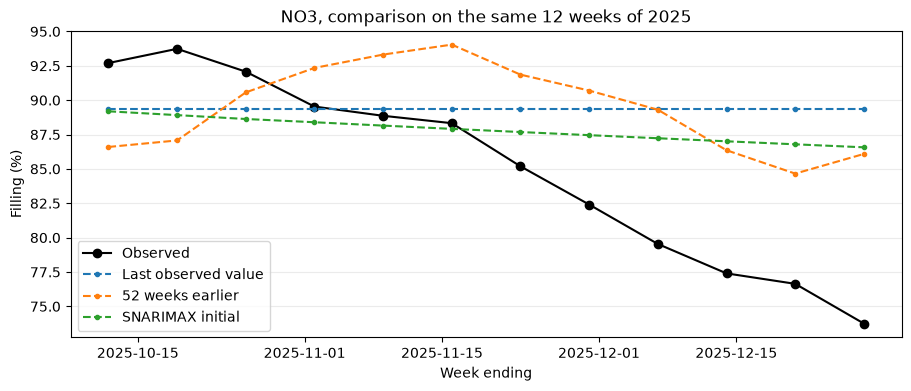

In [22]:
# Draw each forecast at the same twelve dates to compare the shape and the errors.
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
ax.plot(forecast_truth.index, forecast_truth * 100, color='black', marker='o', label='Observed')
for name in benchmark_forecasts:
    ax.plot(benchmark_forecasts.index, benchmark_forecasts[name] * 100,
            linestyle='--', marker='.', label=name)
ax.set(title='NO3, comparison on the same 12 weeks of 2025', xlabel='Week ending', ylabel='Filling (%)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

### 3.3 Test the seasonal terms separately

Use the same NO3 training period and 12-week horizon. Hold p=3, d=1 and q=3 fixed. Set m=52, corresponding to an approximately annual pattern in weekly data, and test a single seasonal autoregressive term (sp=1), first seasonal differencing (sd=1), and a single seasonal error term (sq=1). Each experiment keeps the other two seasonal orders at zero. The regressor and its training loop retain River's defaults from section 3.1.

This is an exploratory comparison on a period whose actual outcomes have already been inspected. Its ranking describes these 12 weeks. Multiple chronological forecast cutoffs are needed before selecting a default setting for the app. [Course description of validation](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/2_ML_approach.ipynb) · [Course River example](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/3_Streaming/2_Streaming_models.ipynb)

In [23]:
# Change one seasonal component at a time so its effect can be inspected.
seasonal_orders = {
    'SNARIMAX seasonal AR': dict(p=3, d=1, q=3, m=52, sp=1, sd=0, sq=0),
    'SNARIMAX seasonal difference': dict(p=3, d=1, q=3, m=52, sp=0, sd=1, sq=0),
    'SNARIMAX seasonal MA': dict(p=3, d=1, q=3, m=52, sp=0, sd=0, sq=1),
}
seasonal_forecasts = pd.DataFrame(index=first_forecast.index)
seasonal_times = {}
for name, orders in seasonal_orders.items():
    started = perf_counter()
    selected_training, prediction = forecast_reservoir_snarimax(
        nve_history, nve_area_type, nve_area_number,
        forecast_train_start, forecast_train_end, forecast_horizon, **orders,
    )
    seasonal_times[name] = perf_counter() - started
    assert selected_training.equals(training_filling)
    assert prediction.index.equals(first_forecast.index)
    seasonal_forecasts[name] = prediction

# Score every forecast against the same observed values, using full precision.
all_forecasts = benchmark_forecasts.join(seasonal_forecasts, validate='one_to_one')
all_errors_pp = all_forecasts.sub(forecast_truth, axis=0) * 100
comparison_scores = pd.DataFrame({
    'MAE (pp)': all_errors_pp.abs().mean(),
    'RMSE (pp)': np.sqrt(all_errors_pp.pow(2).mean()),
    'Last-week error (pp)': all_errors_pp.iloc[-1],
}).rename_axis('Forecast')
assert np.isfinite(all_forecasts.to_numpy()).all()
comparison_scores.round(2)

,MAE (pp),RMSE (pp),Last-week error (pp)
Forecast,,,
Last observed value,6.11,7.90,15.60
52 weeks earlier,6.77,7.36,12.34
SNARIMAX initial,5.15,6.45,12.82
SNARIMAX seasonal AR,5.32,6.51,12.05
SNARIMAX seasonal difference,8.19,9.11,14.80
SNARIMAX seasonal MA,5.04,6.44,12.82


In [24]:
# List orders and model runtimes alongside the error comparison above.
experiment_settings = pd.DataFrame.from_dict(
    {'SNARIMAX initial': snarimax_orders, **seasonal_orders}, orient='index',
)
experiment_settings['Training and forecast seconds'] = pd.Series({
    'SNARIMAX initial': forecast_runtime, **seasonal_times,
})
experiment_settings.rename_axis('SNARIMAX experiment').round(4)

,p,d,q,m,sp,sd,sq,Training and forecast seconds
SNARIMAX experiment,,,,,,,,
SNARIMAX initial,3,1,3,1,0,0,0,0.0039
SNARIMAX seasonal AR,3,1,3,52,1,0,0,0.0029
SNARIMAX seasonal difference,3,1,3,52,0,1,0,0.0018
SNARIMAX seasonal MA,3,1,3,52,0,0,1,0.0021


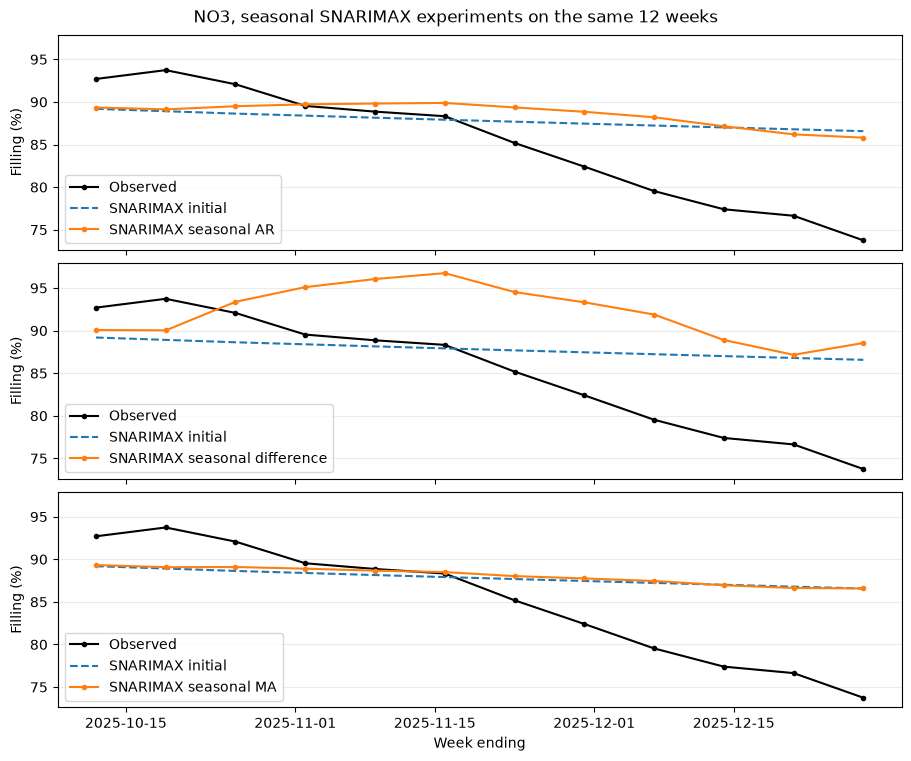

In [25]:
# Each panel compares one seasonal term with the initial model and observed filling.
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True, sharey=True, layout='constrained')
for ax, name in zip(axes, seasonal_orders):
    ax.plot(forecast_truth.index, forecast_truth * 100, color='black', marker='.', label='Observed')
    ax.plot(first_forecast.index, first_forecast * 100, linestyle='--', label='SNARIMAX initial')
    ax.plot(seasonal_forecasts.index, seasonal_forecasts[name] * 100, marker='.', label=name)
    ax.set(ylabel='Filling (%)')
    ax.legend(loc='lower left')
    ax.grid(axis='y', alpha=0.25)
axes[-1].set_xlabel('Week ending')
fig.suptitle('NO3, seasonal SNARIMAX experiments on the same 12 weeks')
plt.show()

#### Comparison findings

For 12 October–28 December 2025, the initial SNARIMAX achieved **5.15 pp MAE**, compared with **6.11 pp** for the last-value forecast and **6.77 pp** for filling 52 weeks earlier. Adding one seasonal error term (sq=1, m=52) lowered MAE to **5.04 pp**. Its last-week error remained **12.82 pp**.

The seasonal autoregressive term (sp=1) gave **5.32 pp MAE**. Seasonal differencing (sd=1) gave **8.19 pp**, the largest MAE among these experiments. A seasonal term therefore needs to be evaluated by its effect on the forecast. These results are specific to this 12-week period. The small seasonal-MA improvement will be checked at several chronological cutoffs before choosing a default.

### 3.4 Compare four forecast cutoffs in 2025

Use the first Sunday of January, April, July and October 2025 as the last training observation. Train a fresh model on the **104 consecutive weeks** ending at each date, then forecast the next 12 weekly observations. The same 104-week history is used for both SNARIMAX variants and both simple forecasts. The four cutoff dates are 5 January, 6 April, 6 July and 5 October.

For each cutoff, compare the initial p=3, d=1, q=3 model, the same model with m=52 and sq=1, the last observed filling, and filling 52 weeks earlier. Score the first **4, 8 and 12 forecast weeks**. Each horizon's MAE and RMSE therefore measure the full forecast path up to that horizon. These are four historical cutoffs, with nested forecast horizons.

The errors below use the recorded observation dates. First API publication and revision timestamps remain unavailable. The October comparison here uses 104 training observations. Sections 3.1–3.3 used 144, so their October model scores can differ. [Course chapter on chronological validation](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/2_ML_approach.ipynb)

In [26]:
# Use the first Sunday of each selected month so the cutoff is an NVE observation date.
backtest_cutoffs = pd.to_datetime(['2025-01-05', '2025-04-06', '2025-07-06', '2025-10-05'])
backtest_train_weeks = 104
backtest_horizons = (4, 8, 12)
backtest_models = {
    'SNARIMAX initial': snarimax_orders,
    'SNARIMAX seasonal MA': seasonal_orders['SNARIMAX seasonal MA'],
}
backtest_runs = []
backtest_periods = []
started = perf_counter()
for cutoff in backtest_cutoffs:
    # Inclusive boundaries need 103 intervals for 104 weekly observations.
    train_start = cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
    forecasts = pd.DataFrame()
    for name, orders in backtest_models.items():
        training, forecast = forecast_reservoir_snarimax(
            nve_history, nve_area_type, nve_area_number,
            train_start, cutoff, max(backtest_horizons), **orders,
        )
        assert len(training) == backtest_train_weeks
        assert training.index[0] == train_start and training.index[-1] == cutoff
        forecasts[name] = forecast

    # Retrieve the seasonal reference only from the selected training window.
    prior_dates = forecasts.index - pd.Timedelta(weeks=52)
    prior_filling = training.reindex(prior_dates)
    assert prior_dates.max() <= cutoff and prior_filling.notna().all()
    forecasts['Last observed value'] = training.iloc[-1]
    forecasts['52 weeks earlier'] = prior_filling.to_numpy()
    assert forecasts.index.min() > cutoff
    assert forecasts.notna().all().all() and np.isfinite(forecasts.to_numpy()).all()

    # Fetch actual values after all forecasts have been made.
    forecasts['Observed'] = observed_filling.reindex(forecasts.index)
    assert forecasts['Observed'].notna().all()
    forecasts['Train end'] = cutoff
    backtest_runs.append(forecasts)
    backtest_periods.append({
        'Train start': train_start, 'Train end': cutoff,
        'First forecast week': forecasts.index[0], 'Last forecast week': forecasts.index[-1],
    })

backtest_predictions = pd.concat(backtest_runs)
backtest_runtime = perf_counter() - started
print(f'Four cutoffs, {backtest_train_weeks} training observations per model, 12 dynamic forecast weeks each.')
print(f'All forecasts computed in {backtest_runtime:.3f} seconds.')
pd.DataFrame(backtest_periods)

Four cutoffs, 104 training observations per model, 12 dynamic forecast weeks each.
All forecasts computed in 0.020 seconds.


,Train start,Train end,First forecast week,Last forecast week
0,2023-01-15,2025-01-05,2025-01-12,2025-03-30
1,2023-04-16,2025-04-06,2025-04-13,2025-06-29
2,2023-07-16,2025-07-06,2025-07-13,2025-09-28
3,2023-10-15,2025-10-05,2025-10-12,2025-12-28


In [27]:
# Equal horizons give the four cutoffs equal weight in the overall comparison.
backtest_forecast_names = ['Last observed value', '52 weeks earlier', *backtest_models]
backtest_scores = []
for cutoff, run in backtest_predictions.groupby('Train end'):
    for horizon in backtest_horizons:
        selected = run.iloc[:horizon]
        errors_pp = selected[backtest_forecast_names].sub(selected['Observed'], axis=0) * 100
        for name in backtest_forecast_names:
            error = errors_pp[name]
            backtest_scores.append({
                'Train end': cutoff, 'Horizon (weeks)': horizon, 'Forecast': name,
                'MAE (pp)': error.abs().mean(), 'MSE (pp squared)': error.pow(2).mean(),
                'RMSE (pp)': np.sqrt(error.pow(2).mean()),
            })

backtest_scores = pd.DataFrame(backtest_scores)
assert len(backtest_scores) == 4 * len(backtest_horizons) * len(backtest_forecast_names)
backtest_summary = backtest_scores.groupby(['Forecast', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
# Pool squared errors before taking the square root for overall RMSE.
backtest_summary['RMSE (pp)'] = np.sqrt(backtest_summary.pop('MSE (pp squared)'))
backtest_summary[['MAE (pp)', 'RMSE (pp)']].unstack('Horizon (weeks)').reindex(backtest_forecast_names).round(2)

MAE (pp)               RMSE (pp)              
Horizon (weeks)            4      8      12        4      8      12
Forecast                                                           
Last observed value      2.88   5.95   9.62      3.63   8.42  13.48
52 weeks earlier        21.32  18.79  17.30     24.73  22.05  20.84
SNARIMAX initial         4.15   6.96  10.56      5.18   8.75  13.38
SNARIMAX seasonal MA     4.29   7.01  10.60      5.28   8.74  13.18

In [28]:
# Inspect the separate periods because the average can hide a seasonal weakness.
backtest_scores.loc[backtest_scores['Horizon (weeks)'].eq(12)].pivot(
    index='Train end', columns='Forecast', values='MAE (pp)',
).reindex(columns=backtest_forecast_names).round(2)

Forecast,Last observed value,52 weeks earlier,SNARIMAX initial,SNARIMAX seasonal MA
Train end,,,,
2025-01-05,17.34,32.38,9.59,11.00
2025-04-06,11.91,19.50,13.84,12.01
2025-07-06,3.11,10.54,15.06,15.35
2025-10-05,6.11,6.77,3.76,4.03


In [29]:
# Check the pooled scores directly from the individual weekly errors.
assert backtest_predictions.groupby('Train end').size().eq(12).all()
for horizon in backtest_horizons:
    pooled = pd.concat([run.iloc[:horizon] for _, run in backtest_predictions.groupby('Train end')])
    errors = pooled[backtest_forecast_names].sub(pooled['Observed'], axis=0) * 100
    expected = backtest_summary.xs(horizon, level='Horizon (weeks)').reindex(backtest_forecast_names)
    np.testing.assert_allclose(expected['MAE (pp)'], errors.abs().mean())
    np.testing.assert_allclose(expected['RMSE (pp)'], np.sqrt(errors.pow(2).mean()))
print('Verified 48 model scores with the same observed values and correctly pooled errors.')

Verified 48 model scores with the same observed values and correctly pooled errors.


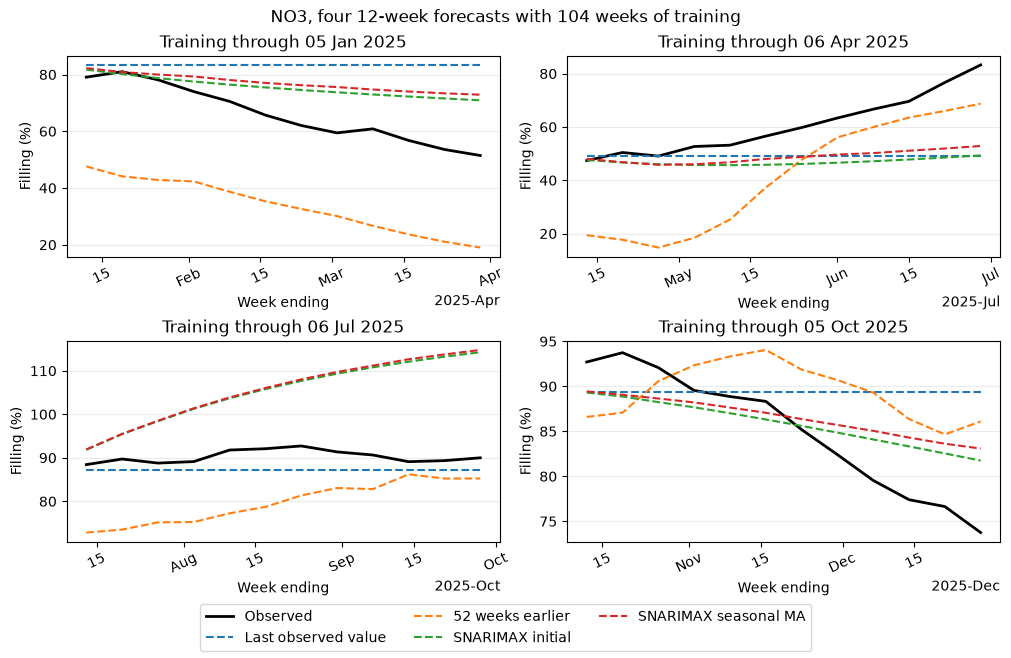

In [30]:
import matplotlib.dates as mdates

# Use the same forecast colours in all four period plots.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout='constrained')
for ax, (cutoff, run) in zip(axes.flat, backtest_predictions.groupby('Train end')):
    ax.plot(run.index, run['Observed'] * 100, color='black', linewidth=2, label='Observed')
    for name in backtest_forecast_names:
        ax.plot(run.index, run[name] * 100, linestyle='--', label=name)
    ax.set(title=f'Training through {cutoff:%d %b %Y}', ylabel='Filling (%)', xlabel='Week ending')
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.25)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=3)
fig.suptitle('NO3, four 12-week forecasts with 104 weeks of training')
plt.show()

#### Findings from the four cutoffs

The last-value forecast had the lowest pooled MAE at all three horizons, with **2.88 pp** over the first 4 weeks, **5.95 pp** over the first 8, and **9.62 pp** over all 12 weeks. The initial SNARIMAX gave **4.15, 6.96 and 10.56 pp**. Adding seasonal MA gave **4.29, 7.01 and 10.60 pp**, so the small improvement seen in section 3.3 did not persist across these periods. At 12 weeks, the seasonal MA model had the lowest pooled RMSE (**13.18 pp**).

The separate 12-week results show where performance changed. The initial SNARIMAX beat the last-value forecast for the January and October cutoffs. It had higher error for April and July, with **15.06 pp** in July compared with **3.11 pp** for the last-value forecast. The July SNARIMAX forecasts rose above 100% while the observations stayed near 90%, showing that these settings extrapolated the summer rise too strongly. Filling 52 weeks earlier was the least accurate method on average in this comparison.

The October initial SNARIMAX score changed from **5.15 pp** in section 3.1 to **3.76 pp** here because the training length changed from 144 to 104 weeks. The four-cutoff test therefore supports checking training length as well as model orders. For the next weather experiment, retain the initial SNARIMAX as the simpler of the two near-equal SNARIMAX candidates and keep the last-value forecast as the strongest MAE reference. These results describe NO3 and the four chosen 2025 periods.

### 3.5 Test weather inputs with an explicit future scenario

Use p=3, d=1, q=3 and the same four cutoffs, 104 training weeks, and 4-, 8- and 12-week horizons as section 3.4. Test temperature, precipitation, and the two together. The function accepts training features through `learn_one(y, x=...)` and future scenario features through `forecast(horizon, xs=...)`.

Pair each filling observation with weather from the **previous week**, the one-week lead examined in section 2. ERA5's documented delay is about five days. For each cutoff, use weather only through the week ending seven days earlier. The forecast dates retain the observation-time convention described in section 1.4.

For every future weather week, compute the mean of the same ISO week in that cutoff's 104-week weather history. The author approved this scenario before running the weather comparison. It assumes that future weather follows those past weekly averages. There are only two observations contributing to each weekly mean. Model scores are conditional on that scenario and the historical release-time limitations. [River exogenous inputs](https://riverml.xyz/dev/api/time-series/SNARIMAX/) · [ERA5 availability](https://open-meteo.com/en/docs/historical-weather-api#data-sources)

In [31]:
# Keep each weather week's ending date so it can be shifted relative to filling.
weather_for_forecasts = weather_weekly_3_years.copy()
weather_for_forecasts.index = pd.DatetimeIndex([
    date.fromisocalendar(year, week, 7) for year, week in weather_for_forecasts.index
], name='observation_date')
weather_for_forecasts = weather_for_forecasts.sort_index()


def prepare_weather_scenario(weather, training_dates, forecast_dates):
    # Each feature describes weather one week before its filling observation.
    weather_training_dates = training_dates - pd.Timedelta(weeks=1)
    known_weather = weather.reindex(weather_training_dates)
    if known_weather.isna().any().any():
        raise ValueError('The selected training period needs complete previous-week weather.')
    assert known_weather.index.max() == training_dates.max() - pd.Timedelta(weeks=1)
    exogenous = known_weather.set_axis(training_dates)

    # The future scenario is built entirely from the weather used for training.
    historical_means = known_weather.groupby(known_weather.index.isocalendar().week.to_numpy()).mean()
    future_weather_dates = forecast_dates - pd.Timedelta(weeks=1)
    future_week_numbers = future_weather_dates.isocalendar().week.to_numpy()
    scenario = historical_means.reindex(future_week_numbers).set_axis(forecast_dates)
    if scenario.isna().any().any():
        raise ValueError('The training history has no weather mean for a required ISO week.')
    quote_count = known_weather.groupby(known_weather.index.isocalendar().week.to_numpy()).size()
    sample_counts = quote_count.reindex(future_week_numbers).set_axis(forecast_dates)
    return exogenous, scenario, sample_counts


weather_variants = {
    'SNARIMAX + temperature': ['temperature_c'],
    'SNARIMAX + precipitation': ['precipitation_mm'],
    'SNARIMAX + both weather inputs': ['temperature_c', 'precipitation_mm'],
}
weather_backtest_runs = []
weather_scenario_audit = []
started = perf_counter()
for cutoff, reference_run in backtest_predictions.groupby('Train end'):
    train_start = cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
    training_dates = pd.date_range(train_start, cutoff, freq='W-SUN', name='observation_date')
    forecast_dates = reference_run.index
    training_x, future_x, sample_counts = prepare_weather_scenario(
        weather_for_forecasts, training_dates, forecast_dates,
    )
    assert sample_counts.eq(2).all()
    forecasts = reference_run[['Observed', 'Last observed value', 'SNARIMAX initial']].copy()
    for name, columns in weather_variants.items():
        training, prediction = forecast_reservoir_snarimax(
            nve_history, nve_area_type, nve_area_number,
            train_start, cutoff, max(backtest_horizons), **snarimax_orders,
            exogenous=training_x[columns], future_exogenous=future_x[columns],
        )
        assert len(training) == backtest_train_weeks and prediction.index.equals(forecast_dates)
        forecasts[name] = prediction
    forecasts['Train end'] = cutoff
    weather_backtest_runs.append(forecasts)
    weather_scenario_audit.append({
        'Train end': cutoff,
        'Last observed weather week': training_dates[-1] - pd.Timedelta(weeks=1),
        'Weeks contributing to each scenario mean': int(sample_counts.min()),
    })
weather_backtest_predictions = pd.concat(weather_backtest_runs)
print(f'Three weather variants at four cutoffs computed in {perf_counter() - started:.3f} seconds.')
pd.DataFrame(weather_scenario_audit)

Three weather variants at four cutoffs computed in 0.070 seconds.


,Train end,Last observed weather week,Weeks contributing to each scenario mean
0,2025-01-05,2024-12-29,2
1,2025-04-06,2025-03-30,2
2,2025-07-06,2025-06-29,2
3,2025-10-05,2025-09-28,2


In [32]:
# Reuse the same horizon definitions and score the same weekly observations.
weather_forecast_names = ['Last observed value', 'SNARIMAX initial', *weather_variants]
weather_backtest_scores = []
for cutoff, run in weather_backtest_predictions.groupby('Train end'):
    for horizon in backtest_horizons:
        selected = run.iloc[:horizon]
        errors_pp = selected[weather_forecast_names].sub(selected['Observed'], axis=0) * 100
        for name in weather_forecast_names:
            error = errors_pp[name]
            weather_backtest_scores.append({
                'Train end': cutoff, 'Horizon (weeks)': horizon, 'Forecast': name,
                'MAE (pp)': error.abs().mean(), 'MSE (pp squared)': error.pow(2).mean(),
            })
weather_backtest_scores = pd.DataFrame(weather_backtest_scores)
assert len(weather_backtest_scores) == 4 * len(backtest_horizons) * len(weather_forecast_names)
weather_backtest_summary = weather_backtest_scores.groupby(['Forecast', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
weather_backtest_summary['RMSE (pp)'] = np.sqrt(weather_backtest_summary.pop('MSE (pp squared)'))
weather_backtest_summary.unstack('Horizon (weeks)').reindex(weather_forecast_names).round(2)

MAE (pp)              RMSE (pp)             
Horizon (weeks)                      4     8      12        4     8      12
Forecast                                                                   
Last observed value                2.88  5.95   9.62      3.63  8.42  13.48
SNARIMAX initial                   4.15  6.96  10.56      5.18  8.75  13.38
SNARIMAX + temperature             4.58  7.30  10.30      5.98  9.86  14.71
SNARIMAX + precipitation           4.35  6.52   9.16      5.47  8.29  11.71
SNARIMAX + both weather inputs     4.50  6.82   9.45      6.13  9.76  14.24

In [33]:
# Compare separate seasons before interpreting the average gain from weather.
weather_backtest_scores.loc[weather_backtest_scores['Horizon (weeks)'].eq(12)].pivot(
    index='Train end', columns='Forecast', values='MAE (pp)',
).reindex(columns=weather_forecast_names).round(2)

Forecast,Last observed value,SNARIMAX initial,SNARIMAX + temperature,SNARIMAX + precipitation,SNARIMAX + both weather inputs
Train end,,,,,
2025-01-05,17.34,9.59,4.24,9.77,3.82
2025-04-06,11.91,13.84,11.34,6.94,6.04
2025-07-06,3.11,15.06,22.46,16.35,23.73
2025-10-05,6.11,3.76,3.18,3.58,4.19


In [34]:
# Alter all later weather and verify the cutoff's training data and scenario stay identical.
first_cutoff = backtest_cutoffs[0]
first_training_dates = pd.date_range(
    first_cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1), first_cutoff,
    freq='W-SUN', name='observation_date',
)
first_forecast_dates = backtest_predictions.loc[backtest_predictions['Train end'].eq(first_cutoff)].index
training_x, scenario_x, _ = prepare_weather_scenario(
    weather_for_forecasts, first_training_dates, first_forecast_dates,
)
changed_weather = weather_for_forecasts.copy()
changed_weather.loc[changed_weather.index > first_cutoff - pd.Timedelta(weeks=1)] = 9999
changed_training, changed_scenario, _ = prepare_weather_scenario(
    changed_weather, first_training_dates, first_forecast_dates,
)
pd.testing.assert_frame_equal(training_x, changed_training)
pd.testing.assert_frame_equal(scenario_x, changed_scenario)

# Both reference scores must be identical to the earlier filling-only backtest.
for name in ('Last observed value', 'SNARIMAX initial'):
    pd.testing.assert_frame_equal(
        weather_backtest_summary.loc[name], backtest_summary.loc[name],
    )
assert np.isfinite(weather_backtest_predictions[weather_forecast_names].to_numpy()).all()
print('Verified that later weather changes neither the training features nor the future scenario.')
print('Both reference scores match section 3.4 exactly.')

Verified that later weather changes neither the training features nor the future scenario.
Both reference scores match section 3.4 exactly.


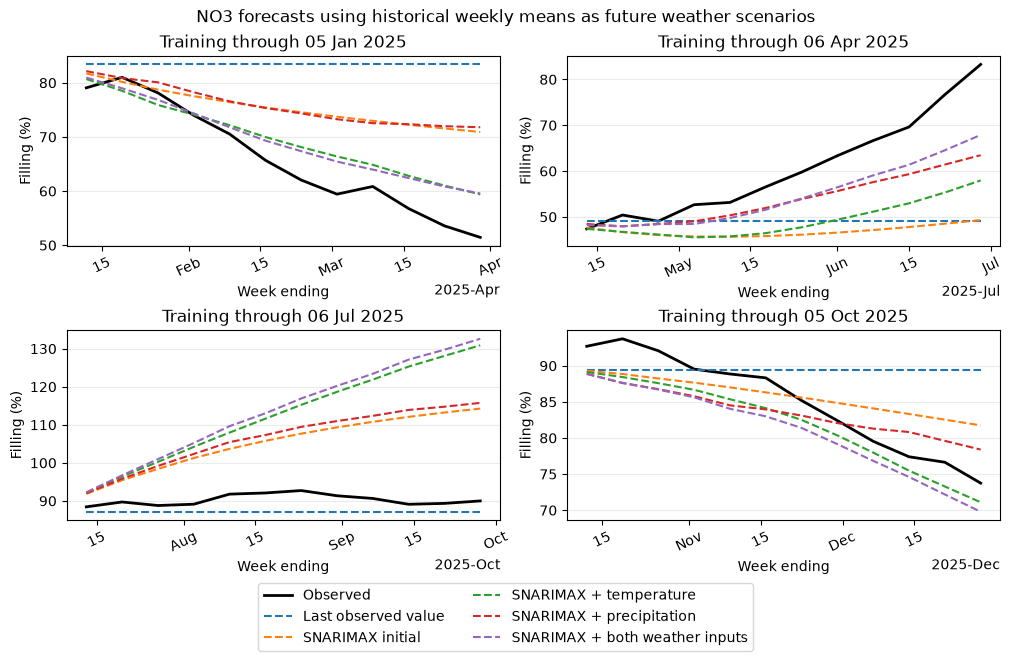

In [35]:
# Inspect how the future weather scenario changes the recursive forecast in each period.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout='constrained')
for ax, (cutoff, run) in zip(axes.flat, weather_backtest_predictions.groupby('Train end')):
    ax.plot(run.index, run['Observed'] * 100, color='black', linewidth=2, label='Observed')
    for name in weather_forecast_names:
        ax.plot(run.index, run[name] * 100, linestyle='--', label=name)
    ax.set(title=f'Training through {cutoff:%d %b %Y}', ylabel='Filling (%)', xlabel='Week ending')
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.25)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=2)
fig.suptitle('NO3 forecasts using historical weekly means as future weather scenarios')
plt.show()

#### Findings from the weather scenario test

Over the 12-week paths, precipitation alone lowered pooled MAE from **10.56 pp** for the filling-only SNARIMAX to **9.16 pp**. The last-value baseline gave **9.62 pp**. Precipitation also gave the lowest pooled 12-week RMSE, **11.71 pp**. At 4 and 8 weeks, the last-value forecast retained the lowest MAE, **2.88 and 5.95 pp**.

The precipitation model performed better than filling-only SNARIMAX at the April and October cutoffs, and worse at January and July. Its July MAE remained **16.35 pp**, compared with **3.11 pp** for the last-value forecast. Temperature alone gave **10.30 pp** pooled 12-week MAE, and both variables gave **9.45 pp**. Both-weather July error reached **23.73 pp**, with forecast filling exceeding 130%.

The comparison supports retaining precipitation as a candidate for longer forecasts. It also shows that gains depend on season and forecast length. These scores apply to the approved future-weather scenario, built from only two past observations per ISO week, and a one-week lag between weather and filling. Performance with other future-weather scenarios remains to be evaluated. The next model choice should consider these errors alongside the filling-only tests before setting Streamlit defaults.

### 3.6 Test training length and differencing

Keep p=3, q=3 and River's default scaler and linear regressor. Compare **104 and 156 training weeks** with **d=0 and d=1** at the same four cutoffs and forecast horizons as section 3.4. This gives four configurations. With d=0, River learns filling levels. With d=1, it learns first differences and accumulates predicted changes to recover filling levels.

The tests investigate whether these two choices reduce the excessive summer rise. Report the forecast ranges as well as MAE and RMSE, because a recursive forecast can move far outside the observed filling range. The same 2025 periods are reused for model development and comparison.

In [36]:
history_experiments = {
    '104 weeks, d=0': {'training_weeks': 104, 'd': 0},
    '104 weeks, d=1': {'training_weeks': 104, 'd': 1},
    '156 weeks, d=0': {'training_weeks': 156, 'd': 0},
    '156 weeks, d=1': {'training_weeks': 156, 'd': 1},
}
history_test_runs = []
started = perf_counter()
for cutoff in backtest_cutoffs:
    forecasts = pd.DataFrame()
    for name, settings in history_experiments.items():
        train_weeks = settings['training_weeks']
        train_start = cutoff - pd.Timedelta(weeks=train_weeks - 1)
        training, prediction = forecast_reservoir_snarimax(
            nve_history, nve_area_type, nve_area_number,
            train_start, cutoff, max(backtest_horizons),
            p=3, d=settings['d'], q=3,
        )
        assert len(training) == train_weeks
        assert training.index[0] == train_start and training.index[-1] == cutoff
        assert prediction.index.min() > cutoff
        forecasts[name] = prediction
    forecasts['Observed'] = observed_filling.reindex(forecasts.index)
    assert forecasts['Observed'].notna().all()
    forecasts['Train end'] = cutoff
    history_test_runs.append(forecasts)
history_test_predictions = pd.concat(history_test_runs)
assert np.isfinite(history_test_predictions[list(history_experiments)].to_numpy()).all()
print(f'Four configurations at four cutoffs computed in {perf_counter() - started:.3f} seconds.')

Four configurations at four cutoffs computed in 0.038 seconds.


In [37]:
history_test_scores = []
for cutoff, run in history_test_predictions.groupby('Train end'):
    for horizon in backtest_horizons:
        selected = run.iloc[:horizon]
        errors_pp = selected[list(history_experiments)].sub(selected['Observed'], axis=0) * 100
        for name in history_experiments:
            error = errors_pp[name]
            history_test_scores.append({
                'Train end': cutoff, 'Horizon (weeks)': horizon, 'Forecast': name,
                'MAE (pp)': error.abs().mean(), 'MSE (pp squared)': error.pow(2).mean(),
            })
history_test_scores = pd.DataFrame(history_test_scores)
assert len(history_test_scores) == 4 * len(backtest_horizons) * len(history_experiments)
history_test_summary = history_test_scores.groupby(['Forecast', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
history_test_summary['RMSE (pp)'] = np.sqrt(history_test_summary.pop('MSE (pp squared)'))
history_test_summary.unstack('Horizon (weeks)').reindex(history_experiments).round(2)

MAE (pp)                 RMSE (pp)                
Horizon (weeks)       4       8       12        4       8       12
Forecast                                                          
104 weeks, d=0     36.46  131.49  458.33     50.59  210.43  846.49
104 weeks, d=1      4.15    6.96   10.56      5.18    8.75   13.38
156 weeks, d=0      7.39   19.11   43.88      8.95   25.88   69.15
156 weeks, d=1      4.32    7.26   10.97      5.36    9.16   14.09

In [38]:
# Report extremes over all 48 forecast observations for each configuration.
history_values = history_test_predictions[list(history_experiments)]
history_forecast_ranges = pd.DataFrame({
    'Lowest forecast (%)': history_values.min() * 100,
    'Highest forecast (%)': history_values.max() * 100,
    'Forecasts below 0%': history_values.lt(0).sum(),
    'Forecasts above 100%': history_values.gt(1).sum(),
})
history_forecast_ranges.rename_axis('Forecast').round(2)

,Lowest forecast (%),Highest forecast (%),Forecasts below 0%,Forecasts above 100%
Forecast,,,,
"104 weeks, d=0",-2919.09,82.30,26,0
"104 weeks, d=1",45.66,114.25,0,9
"156 weeks, d=0",-200.56,87.61,9,0
"156 weeks, d=1",43.69,114.22,0,9


In [39]:
# The retained configuration must reproduce the earlier filling-only backtest.
pd.testing.assert_frame_equal(
    history_test_summary.loc['104 weeks, d=1'], backtest_summary.loc['SNARIMAX initial'],
)
history_test_scores.loc[history_test_scores['Horizon (weeks)'].eq(12)].pivot(
    index='Train end', columns='Forecast', values='MAE (pp)',
).reindex(columns=history_experiments).round(2)

Forecast,"104 weeks, d=0","104 weeks, d=1","156 weeks, d=0","156 weeks, d=1"
Train end,,,,
2025-01-05,394.69,9.59,29.06,8.95
2025-04-06,741.01,13.84,16.39,16.04
2025-07-06,14.28,15.06,52.82,15.07
2025-10-05,683.33,3.76,77.26,3.81


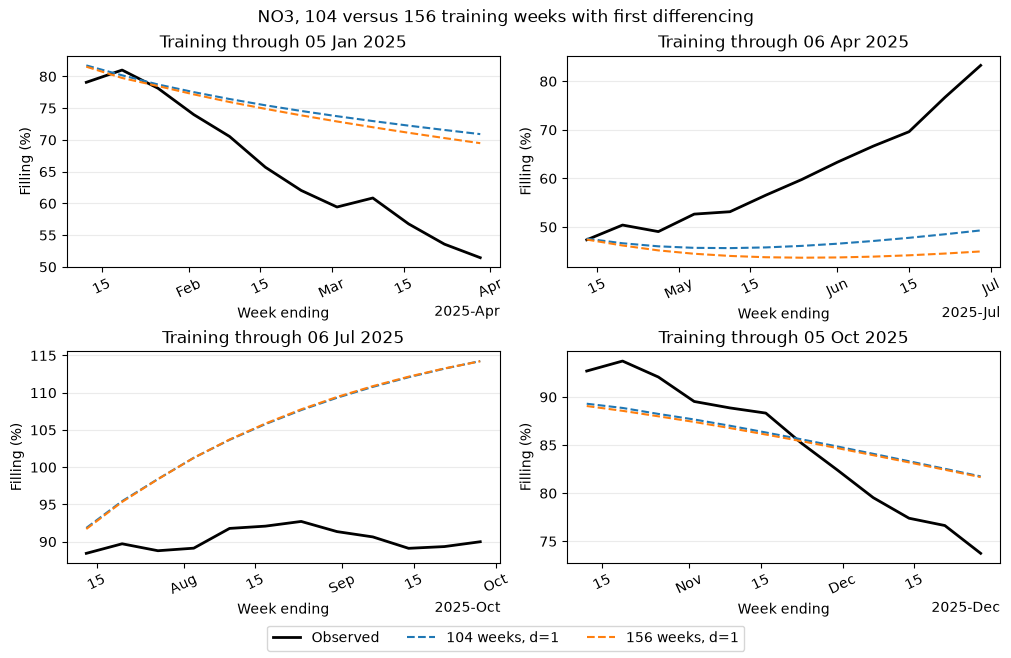

In [40]:
# Compare the two first-differenced configurations against observations in each season.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout='constrained')
for ax, (cutoff, run) in zip(axes.flat, history_test_predictions.groupby('Train end')):
    ax.plot(run.index, run['Observed'] * 100, color='black', linewidth=2, label='Observed')
    for name in ('104 weeks, d=1', '156 weeks, d=1'):
        ax.plot(run.index, run[name] * 100, linestyle='--', label=name)
    ax.set(title=f'Training through {cutoff:%d %b %Y}', ylabel='Filling (%)', xlabel='Week ending')
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.25)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=3)
fig.suptitle('NO3, 104 versus 156 training weeks with first differencing')
plt.show()

#### Findings from training length and differencing

Among these four filling-only configurations, 104 training weeks with d=1 retained the lowest 12-week MAE, **10.56 pp**. Increasing history to 156 weeks with d=1 gave **10.97 pp**. July errors were almost identical, **15.06 and 15.07 pp**, and both July forecast paths exceeded 100%.

With p=3, q=3 and the default scaler and linear regressor retained, d=0 produced large negative recursive forecasts. Its pooled 12-week MAE was **458.33 pp** with 104 training weeks and **43.88 pp** with 156. A direct River learn-one and forecast loop reproduced these paths when checked separately. These results concern the tested configuration with River's default regressor.

The experiment therefore retains **104 weeks, p=3, d=1, q=3** as the filling-only comparison for the next stage. Section 3.5 already contains the precipitation experiment for exactly that configuration, with **9.16 pp** pooled 12-week MAE. The excessive July rise remains a weakness to investigate in the model's dynamics.

### 3.7 Check the fixed candidates in January–March 2026

Retain **104 training weeks, p=3, d=1 and q=3**. Train through **4 January 2026** and forecast **11 January–29 March 2026**. Compare the last observed filling, the filling-only SNARIMAX and SNARIMAX with previous-week precipitation. Evaluate the first 4, 8 and 12 forecast weeks using the same MAE and RMSE definitions as before.

The period and candidates were selected before inspecting the 2026 forecast errors. The precipitation scenario uses the previously approved mean for each corresponding ISO week, calculated from that cutoff's training weather. Its last observed weather week ends on **28 December 2025**. The existing 2023–2025 weather file covers the required history. Observation dates and historical release-time limitations follow section 1.4.

In [41]:
validation_cutoff = pd.Timestamp('2026-01-04')
validation_start = validation_cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
validation_training, validation_initial = forecast_reservoir_snarimax(
    nve_history, nve_area_type, nve_area_number,
    validation_start, validation_cutoff, max(backtest_horizons), **snarimax_orders,
)
assert len(validation_training) == 104
assert validation_training.index[0] == pd.Timestamp('2024-01-14')
assert validation_initial.index[0] == pd.Timestamp('2026-01-11')
assert validation_initial.index[-1] == pd.Timestamp('2026-03-29')

validation_training_x, validation_future_x, validation_counts = prepare_weather_scenario(
    weather_for_forecasts, validation_training.index, validation_initial.index,
)
assert validation_counts.eq(2).all()
_, validation_precipitation = forecast_reservoir_snarimax(
    nve_history, nve_area_type, nve_area_number,
    validation_start, validation_cutoff, max(backtest_horizons), **snarimax_orders,
    exogenous=validation_training_x[['precipitation_mm']],
    future_exogenous=validation_future_x[['precipitation_mm']],
)
validation_predictions = pd.DataFrame({
    'Last observed value': validation_training.iloc[-1],
    'SNARIMAX initial': validation_initial,
    'SNARIMAX + precipitation': validation_precipitation,
})
assert np.isfinite(validation_predictions.to_numpy()).all()

# Load the 2026 observations only after the three forecast paths are fixed.
validation_observed = observed_filling.reindex(validation_predictions.index)
assert validation_observed.notna().all()
print(f'Training from {validation_start:%d %B %Y} through {validation_cutoff:%d %B %Y}, 104 observations.')
print('Last observed weather week ends 28 December 2025; each scenario mean uses two observations.')
validation_predictions.join(validation_observed.rename('Observed')).mul(100).round(2)

Training from 14 January 2024 through 04 January 2026, 104 observations.
Last observed weather week ends 28 December 2025; each scenario mean uses two observations.


,Last observed value,SNARIMAX initial,SNARIMAX + precipitation,Observed
observation_date,,,,
2026-01-11,69.74,66.85,67.00,65.26
2026-01-18,69.74,63.96,64.30,60.78
2026-01-25,69.74,61.47,61.82,55.78
2026-02-01,69.74,59.52,59.68,50.83
2026-02-08,69.74,57.80,57.70,46.20
2026-02-15,69.74,56.33,56.44,41.38
2026-02-22,69.74,55.08,55.70,37.49
2026-03-01,69.74,53.99,55.05,33.92
2026-03-08,69.74,53.04,54.28,31.46


In [42]:
validation_scores = []
for horizon in backtest_horizons:
    errors_pp = validation_predictions.iloc[:horizon].sub(validation_observed.iloc[:horizon], axis=0) * 100
    for name in validation_predictions:
        error = errors_pp[name]
        validation_scores.append({
            'Forecast': name, 'Horizon (weeks)': horizon,
            'MAE (pp)': error.abs().mean(), 'RMSE (pp)': np.sqrt(error.pow(2).mean()),
        })
validation_scores = pd.DataFrame(validation_scores)
assert len(validation_scores) == len(validation_predictions.columns) * len(backtest_horizons)
validation_scores.set_index(['Forecast', 'Horizon (weeks)']).unstack('Horizon (weeks)').reindex(
    validation_predictions.columns,
).round(2)

MAE (pp)               RMSE (pp)              
Horizon (weeks)                4      8      12        4      8      12
Last observed value         11.58  20.79  27.45     12.78  23.28  30.27
SNARIMAX initial             4.79  10.42  14.58      5.49  12.20  16.56
SNARIMAX + precipitation     5.04  10.76  15.20      5.70  12.59  17.30

In [43]:
# Reproduce both model forecasts with all future NVE target rows removed.
validation_history = nve_history.loc[nve_history['observation_date'] <= validation_cutoff]
_, validation_repeat = forecast_reservoir_snarimax(
    validation_history, nve_area_type, nve_area_number,
    validation_start, validation_cutoff, max(backtest_horizons), **snarimax_orders,
)
pd.testing.assert_series_equal(validation_initial, validation_repeat)
_, validation_precipitation_repeat = forecast_reservoir_snarimax(
    validation_history, nve_area_type, nve_area_number,
    validation_start, validation_cutoff, max(backtest_horizons), **snarimax_orders,
    exogenous=validation_training_x[['precipitation_mm']],
    future_exogenous=validation_future_x[['precipitation_mm']],
)
pd.testing.assert_series_equal(validation_precipitation, validation_precipitation_repeat)
assert validation_cutoff < validation_predictions.index.min()
print('Both model forecasts are identical after removing all NVE observations after the training cutoff.')

Both model forecasts are identical after removing all NVE observations after the training cutoff.


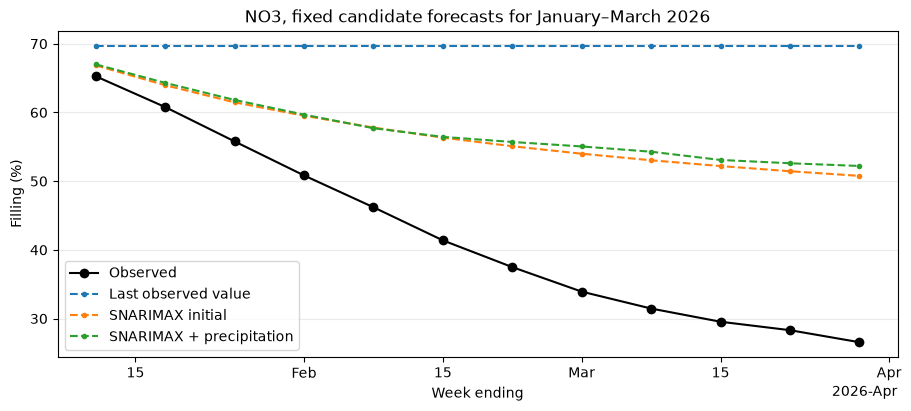

In [44]:
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.plot(validation_observed.index, validation_observed * 100, color='black', marker='o', label='Observed')
for name in validation_predictions:
    ax.plot(validation_predictions.index, validation_predictions[name] * 100,
            linestyle='--', marker='.', label=name)
ax.set(title='NO3, fixed candidate forecasts for January–March 2026',
       xlabel='Week ending', ylabel='Filling (%)')
locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

#### Findings from the 2026 check

For January–March 2026, the filling-only SNARIMAX achieved MAE of **4.79, 10.42 and 14.58 pp** over the first 4, 8 and 12 weeks. The precipitation variant gave **5.04, 10.76 and 15.20 pp**, and the last-value forecast gave **11.58, 20.79 and 27.45 pp**. Filling-only SNARIMAX also had the lowest RMSE at all three horizons.

For 29 March, filling-only SNARIMAX predicted **50.77%**, the precipitation variant predicted **52.21%**, and observed filling was **26.56%**. Both models captured the direction and underestimated the magnitude of the decline.

The precipitation benefit seen in the four 2025 development periods did not persist in this winter check. Retain the filling-only model as the reference when presenting the weather option, and report the dependence on forecast period, horizon and the two-observation weather scenario. This check covers one winter period. The summer weakness documented in sections 3.4–3.6 remains relevant to the app's interpretation.

### 3.8 Search a fixed set of model orders

Keep **104 training weeks**, **d=1** and River's default scaler and linear regressor. Test **p in {1, 3, 6, 12}** and **q in {0, 1, 3}**. The autoregressive choices span roughly one week to three months of recent changes. Compare each pair with no seasonal term, one seasonal autoregressive term, first seasonal differencing, and one seasonal error term. This is **48 configurations**, including the initial p=3, q=3 setup.

Each configuration uses the same four 2025 cutoffs. Rank by pooled **12-week MAE**, with 12-week RMSE as the tie-breaker, because the assignment asks for forecasts over the coming months. Keep 4- and 8-week scores available for context. Also report forecast extremes.

Freeze the selected orders before evaluating 2026. The January–March 2026 result has already been inspected in section 3.7, so revisiting it is a comparison on a known period. Add cutoffs **5 April and 5 July 2026** for checks on two further seasons. All dates use the observation-time convention and availability limitations from section 1.4.

In [45]:
from itertools import product

# Declare the complete search before evaluating any configuration.
order_seasons = {
    'none': dict(m=1, sp=0, sd=0, sq=0),
    'AR': dict(m=52, sp=1, sd=0, sq=0),
    'difference': dict(m=52, sp=0, sd=1, sq=0),
    'MA': dict(m=52, sp=0, sd=0, sq=1),
}
order_candidates = {
    f'p={p}, q={q}, season={season}': dict(p=p, d=1, q=q, **season_orders)
    for p, q, (season, season_orders) in product((1, 3, 6, 12), (0, 1, 3), order_seasons.items())
}
assert len(order_candidates) == 48
order_search_scores = []
order_search_extremes = []
started = perf_counter()
for name, orders in order_candidates.items():
    fold_predictions = []
    for cutoff, reference in backtest_predictions.groupby('Train end'):
        train_start = cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
        training, prediction = forecast_reservoir_snarimax(
            nve_history, nve_area_type, nve_area_number,
            train_start, cutoff, max(backtest_horizons), **orders,
        )
        assert len(training) == backtest_train_weeks and prediction.index.equals(reference.index)
        fold_predictions.append(prediction)
        for horizon in backtest_horizons:
            errors_pp = (prediction.iloc[:horizon] - reference['Observed'].iloc[:horizon]) * 100
            order_search_scores.append({
                'Candidate': name, 'Train end': cutoff, 'Horizon (weeks)': horizon,
                'MAE (pp)': errors_pp.abs().mean(), 'MSE (pp squared)': errors_pp.pow(2).mean(),
            })
    all_values = pd.concat(fold_predictions)
    order_search_extremes.append({
        'Candidate': name, 'Lowest forecast (%)': all_values.min() * 100,
        'Highest forecast (%)': all_values.max() * 100,
        'Forecasts below 0%': int(all_values.lt(0).sum()),
        'Forecasts above 100%': int(all_values.gt(1).sum()),
    })
order_search_scores = pd.DataFrame(order_search_scores)
assert len(order_search_scores) == 48 * 4 * len(backtest_horizons)
order_search_summary = order_search_scores.groupby(['Candidate', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
order_search_summary['RMSE (pp)'] = np.sqrt(order_search_summary.pop('MSE (pp squared)'))
order_ranking = order_search_summary.xs(12, level='Horizon (weeks)').join(
    pd.DataFrame(order_search_extremes).set_index('Candidate'),
).sort_values(['MAE (pp)', 'RMSE (pp)'])
selected_candidate = order_ranking.index[0]
selected_orders = order_candidates[selected_candidate].copy()
print(f'Evaluated 48 configurations on four 2025 cutoffs in {perf_counter() - started:.3f} seconds.')
print(f'Selected by 2025 twelve-week errors: {selected_candidate}')
order_ranking.head(8).round(2)

Evaluated 48 configurations on four 2025 cutoffs in 0.423 seconds.
Selected by 2025 twelve-week errors: p=1, q=1, season=AR


,MAE (pp),RMSE (pp),Lowest forecast (%),Highest forecast (%),Forecasts below 0%,Forecasts above 100%
Candidate,,,,,,
"p=1, q=1, season=AR",5.21,6.80,47.70,95.07,0,0
"p=1, q=0, season=AR",5.50,6.70,47.18,97.47,0,0
"p=1, q=3, season=AR",5.62,7.43,48.59,94.96,0,0
"p=1, q=1, season=MA",6.99,9.79,47.37,93.85,0,0
"p=1, q=0, season=MA",7.28,9.37,46.90,97.29,0,0
"p=1, q=3, season=MA",7.29,10.20,48.22,93.58,0,0
"p=1, q=3, season=none",7.36,10.61,48.21,92.58,0,0
"p=1, q=1, season=none",7.60,11.09,47.33,92.39,0,0


In [46]:
# Check that the search reproduces the initial setup before using its selected orders.
pd.testing.assert_frame_equal(
    order_search_summary.loc['p=3, q=3, season=none'], backtest_summary.loc['SNARIMAX initial'],
)
selected_2025_scores = order_search_summary.loc[selected_candidate]
pd.concat({
    'Last observed value': backtest_summary.loc['Last observed value'],
    'Initial SNARIMAX': backtest_summary.loc['SNARIMAX initial'],
    'Selected SNARIMAX': selected_2025_scores,
}, names=['Forecast']).unstack('Horizon (weeks)').round(2)

MAE (pp)              RMSE (pp)             
Horizon (weeks)           4     8      12        4     8      12
Forecast                                                        
Last observed value     2.88  5.95   9.62      3.63  8.42  13.48
Initial SNARIMAX        4.15  6.96  10.56      5.18  8.75  13.38
Selected SNARIMAX       2.27  3.18   5.21      2.62  4.29   6.80

In [47]:
# Select no further orders during this comparison with the 2026 outcomes.
order_check_cutoffs = pd.to_datetime(['2026-01-04', '2026-04-05', '2026-07-05'])
order_check_runs = []
for cutoff in order_check_cutoffs:
    train_start = cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
    predictions = pd.DataFrame()
    for name, orders in {'Initial SNARIMAX': snarimax_orders, 'Selected SNARIMAX': selected_orders}.items():
        training, prediction = forecast_reservoir_snarimax(
            nve_history, nve_area_type, nve_area_number,
            train_start, cutoff, max(backtest_horizons), **orders,
        )
        assert len(training) == backtest_train_weeks and training.index[-1] == cutoff
        predictions[name] = prediction
    predictions['Last observed value'] = training.iloc[-1]
    predictions['Observed'] = observed_filling.reindex(predictions.index)
    assert predictions['Observed'].notna().all()
    predictions['Train end'] = cutoff
    order_check_runs.append(predictions)
order_check_predictions = pd.concat(order_check_runs)

order_check_scores = []
for cutoff, run in order_check_predictions.groupby('Train end'):
    for horizon in backtest_horizons:
        selected = run.iloc[:horizon]
        errors_pp = selected[['Last observed value', 'Initial SNARIMAX', 'Selected SNARIMAX']].sub(selected['Observed'], axis=0) * 100
        for name in errors_pp:
            error = errors_pp[name]
            order_check_scores.append({
                'Train end': cutoff, 'Horizon (weeks)': horizon, 'Forecast': name,
                'MAE (pp)': error.abs().mean(), 'MSE (pp squared)': error.pow(2).mean(),
            })
order_check_scores = pd.DataFrame(order_check_scores)
order_check_scores.loc[order_check_scores['Horizon (weeks)'].eq(12)].pivot(
    index='Train end', columns='Forecast', values='MAE (pp)',
).round(2)

Forecast,Initial SNARIMAX,Last observed value,Selected SNARIMAX
Train end,,,
2026-01-04,14.58,27.45,18.21
2026-04-05,13.70,11.13,7.89
2026-07-05,1.96,5.86,4.45


In [48]:
# Report each horizon across the three check periods, retaining the separate-period table above.
order_check_summary = order_check_scores.groupby(['Forecast', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
order_check_summary['RMSE (pp)'] = np.sqrt(order_check_summary.pop('MSE (pp squared)'))
order_check_summary.unstack('Horizon (weeks)').round(2)

MAE (pp)              RMSE (pp)              
Horizon (weeks)           4     8      12        4      8      12
Forecast                                                         
Initial SNARIMAX        2.86  5.83  10.08      3.70   8.50  14.44
Last observed value     4.88  9.33  14.81      7.51  14.01  20.14
Selected SNARIMAX       2.78  6.01  10.18      4.66   9.40  13.93

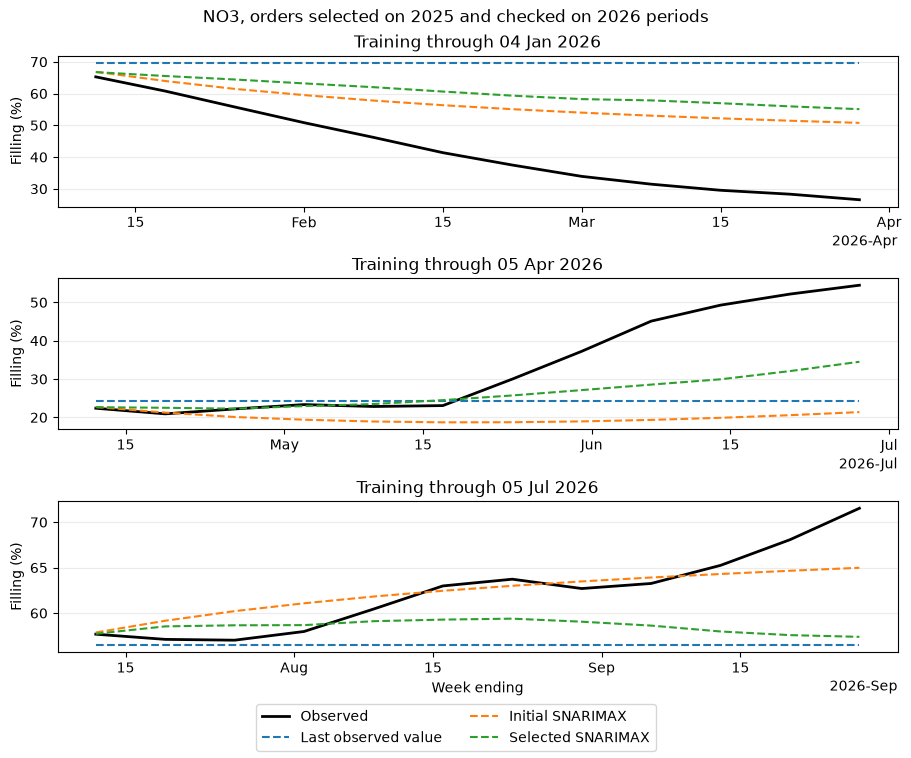

In [49]:
# Plot the selected forecast against its initial settings and the observed path.
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), layout='constrained')
for ax, (cutoff, run) in zip(axes, order_check_predictions.groupby('Train end')):
    ax.plot(run.index, run['Observed'] * 100, color='black', linewidth=2, label='Observed')
    for name in ('Last observed value', 'Initial SNARIMAX', 'Selected SNARIMAX'):
        ax.plot(run.index, run[name] * 100, linestyle='--', label=name)
    ax.set(title=f'Training through {cutoff:%d %b %Y}', ylabel='Filling (%)')
    ax.grid(axis='y', alpha=0.25)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=2)
axes[-1].set_xlabel('Week ending')
fig.suptitle('NO3, orders selected on 2025 and checked on 2026 periods')
plt.show()

#### Findings from the fixed order search

The lowest 2025 12-week MAE among the 48 configurations came from **p=1, d=1, q=1, m=52, sp=1, sd=0, sq=0**, using 104 training weeks. It gave **5.21 pp MAE** and **6.80 pp RMSE**, compared with **10.56 pp** and **13.38 pp** for the initial model. Its 2025 forecast values ranged from **47.70% to 95.07%**. The 4- and 8-week MAEs improved from **4.15 and 6.96 pp** to **2.27 and 3.18 pp**.

On the previously inspected January 2026 cutoff, the selected model's 12-week MAE was **18.21 pp**, compared with **14.58 pp** for the initial model. At the new April cutoff it improved from **13.70 to 7.89 pp**, while at the new July cutoff it increased from **1.96 to 4.45 pp**. Averaged over the two new cutoffs, MAE fell from about **7.83 to 6.17 pp**. Including the known January cutoff gave **10.08 pp** for the initial model and **10.18 pp** for the selected model.

The search found a substantially better fit across the 2025 development periods and improved the average of the two added 2026 checks. Performance still varied by season. The selected orders are a candidate for the app, and the tables retain the initial model and last-value reference so their differences remain visible. The 2026 outcomes were evaluated with the orders frozen at the end of the 2025 search.

### 3.9 Compare the selected orders with and without precipitation

Freeze **p=1, d=1, q=1, m=52, sp=1, sd=0 and sq=0**, with **104 training weeks**. Compare filling-only SNARIMAX, the same model with previous-week precipitation, and the last-value reference on the four 2025 development periods and January–March 2026.

Use the approved future-weather scenario from section 3.5. Each future precipitation input is a mean for the corresponding ISO week, calculated from the two prior observations in that cutoff's training weather history. Report the 2025 average and the already-inspected winter 2026 period separately. This comparison retains the model orders selected in section 3.8.

In [50]:
candidate_weather_orders = dict(p=1, d=1, q=1, m=52, sp=1, sd=0, sq=0)
candidate_weather_cutoffs = backtest_cutoffs.append(pd.DatetimeIndex([validation_cutoff]))
candidate_weather_runs = []
for cutoff in candidate_weather_cutoffs:
    train_start = cutoff - pd.Timedelta(weeks=backtest_train_weeks - 1)
    training, base_forecast = forecast_reservoir_snarimax(
        nve_history, nve_area_type, nve_area_number,
        train_start, cutoff, max(backtest_horizons), **candidate_weather_orders,
    )
    training_x, future_x, sample_counts = prepare_weather_scenario(
        weather_for_forecasts, training.index, base_forecast.index,
    )
    assert len(training) == 104 and sample_counts.eq(2).all()
    weather_training, precipitation_forecast = forecast_reservoir_snarimax(
        nve_history, nve_area_type, nve_area_number,
        train_start, cutoff, max(backtest_horizons), **candidate_weather_orders,
        exogenous=training_x[['precipitation_mm']], future_exogenous=future_x[['precipitation_mm']],
    )
    assert training.equals(weather_training) and base_forecast.index.equals(precipitation_forecast.index)
    run = pd.DataFrame({
        'Last observed value': training.iloc[-1],
        'Selected SNARIMAX': base_forecast,
        'Selected SNARIMAX + precipitation': precipitation_forecast,
    })
    assert np.isfinite(run.to_numpy()).all()
    run['Observed'] = observed_filling.reindex(run.index)
    assert run['Observed'].notna().all() and run.index.min() > cutoff
    run['Train end'] = cutoff
    candidate_weather_runs.append(run)
candidate_weather_predictions = pd.concat(candidate_weather_runs)

candidate_weather_scores = []
for cutoff, run in candidate_weather_predictions.groupby('Train end'):
    for horizon in backtest_horizons:
        errors_pp = run.iloc[:horizon][['Last observed value', 'Selected SNARIMAX', 'Selected SNARIMAX + precipitation']].sub(
            run['Observed'].iloc[:horizon], axis=0,
        ) * 100
        for name in errors_pp:
            error = errors_pp[name]
            candidate_weather_scores.append({
                'Train end': cutoff, 'Evaluation year': cutoff.year, 'Horizon (weeks)': horizon,
                'Forecast': name, 'MAE (pp)': error.abs().mean(), 'MSE (pp squared)': error.pow(2).mean(),
            })
candidate_weather_scores = pd.DataFrame(candidate_weather_scores)
assert len(candidate_weather_scores) == 5 * len(backtest_horizons) * 3
candidate_weather_summary = candidate_weather_scores.groupby(['Evaluation year', 'Forecast', 'Horizon (weeks)']).agg(
    **{'MAE (pp)': ('MAE (pp)', 'mean'), 'MSE (pp squared)': ('MSE (pp squared)', 'mean')}
)
candidate_weather_summary['RMSE (pp)'] = np.sqrt(candidate_weather_summary.pop('MSE (pp squared)'))
candidate_weather_summary.loc[2025].unstack('Horizon (weeks)').round(2)

MAE (pp)             RMSE (pp)             
Horizon (weeks)                         4     8     12        4     8      12
Forecast                                                                     
Last observed value                   2.88  5.95  9.62      3.63  8.42  13.48
Selected SNARIMAX                     2.27  3.18  5.21      2.62  4.29   6.80
Selected SNARIMAX + precipitation     2.75  3.44  4.60      3.37  4.45   6.11

In [51]:
# Keep the known 2026 winter check visible as its own period.
candidate_weather_summary.loc[2026].unstack('Horizon (weeks)').round(2)

MAE (pp)               RMSE (pp)         \
Horizon (weeks)                         4      8      12        4      8    
Forecast                                                                    
Last observed value                  11.58  20.79  27.45     12.78  23.28   
Selected SNARIMAX                     6.82  13.57  18.21      7.95  15.59   
Selected SNARIMAX + precipitation     7.14  14.07  19.19      8.22  16.19   

                                          
Horizon (weeks)                       12  
Forecast                                  
Last observed value                30.27  
Selected SNARIMAX                  20.35  
Selected SNARIMAX + precipitation  21.53

In [52]:
# Check the unchanged filling-only scores against the preceding order search.
pd.testing.assert_frame_equal(
    candidate_weather_summary.loc[(2025, 'Selected SNARIMAX')],
    order_search_summary.loc['p=1, q=1, season=AR'],
)
candidate_weather_periods = candidate_weather_scores.loc[candidate_weather_scores['Horizon (weeks)'].eq(12)].pivot(
    index='Train end', columns='Forecast', values='MAE (pp)',
)
candidate_weather_periods.round(2)

Forecast,Last observed value,Selected SNARIMAX,Selected SNARIMAX + precipitation
Train end,,,
2025-01-05,17.34,8.19,8.63
2025-04-06,11.91,5.14,2.66
2025-07-06,3.11,2.70,2.82
2025-10-05,6.11,4.79,4.28
2026-01-04,27.45,18.21,19.19


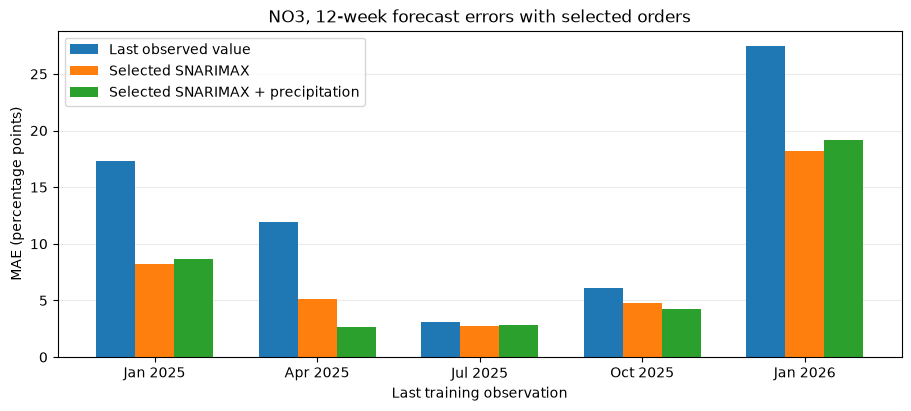

In [53]:
# Compare the twelve-week errors by period, including the same last-value reference.
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
positions = np.arange(len(candidate_weather_periods))
width = 0.24
for offset, name in enumerate(candidate_weather_periods.columns):
    ax.bar(positions + (offset - 1) * width, candidate_weather_periods[name], width=width, label=name)
ax.set_xticks(positions, candidate_weather_periods.index.strftime('%b %Y'))
ax.set(title='NO3, 12-week forecast errors with selected orders',
       xlabel='Last training observation', ylabel='MAE (percentage points)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.show()

#### Final weather comparison and proposed app settings

With the selected orders, adding precipitation reduced pooled 2025 12-week MAE from **5.21 to 4.60 pp** and RMSE from **6.80 to 6.11 pp**. The improvement was concentrated in the April and October cutoffs. Filling-only SNARIMAX had lower 4- and 8-week errors over the 2025 periods.

In the already-inspected winter 2026 check, filling-only SNARIMAX had lower error at all three horizons. Its 12-week MAE was **18.21 pp**, compared with **19.19 pp** for precipitation. This comparison therefore supports presenting precipitation as a scenario-dependent option. The historical-means scenario remains based on two observations per corresponding ISO week.

Proposed initial app settings are **NO3, 104 training weeks, a 12-week horizon, p=1, d=1, q=1, m=52, sp=1, sd=0 and sq=0**. Use filling history as the initial source and expose precipitation as a selectable input with the scenario explained. The filling-only starting choice reflects its lower shorter-horizon and winter-check errors. The report and app should retain the 2025 12-week precipitation advantage and the model's seasonal limitations.

## 4. Streamlit design sketch

Prepare the sketch before restructuring the Streamlit application. The author requested **blue as the main colour** and a layout inspired by the previously peer-reviewed [Vilde dashboard](https://github.com/vildeskobba/IND320vilde). Retain the useful ideas of an area map beside its selector, clear navigation and direct home-page buttons for the main tasks.

Use blue for selected navigation, the selected map area and reservoir/forecast lines. Use a solid line for training observations and a dashed line for the forecast, with observed holdout values labelled separately. Support readable light and dark appearances. The app keeps its existing English interface.

The clickable preview focuses on electricity price areas. It uses simplified boundaries from the project's NVE `budomraader` shapefile, transformed from EPSG:25833 to longitude/latitude and projected for display. The reservoir curves use saved NVE observations. Forecast examples use the selected filling-only SNARIMAX orders with 104 training weeks through 5 October 2025. These are historical design examples; the model evaluation and default choice remain those reported in section 3. NO3 is the evaluated example. Predictions displayed for other areas do not establish their forecasting accuracy.

This section records a design proposal. The Streamlit restructuring and Part 4 interfaces are the next implementation work.

The author approved the blue layout and requested removal of the small footer text. Keep source information on Sources & about and leave the bottom of the content area and sidebar clear.

### 4.1 Home and shared area selection

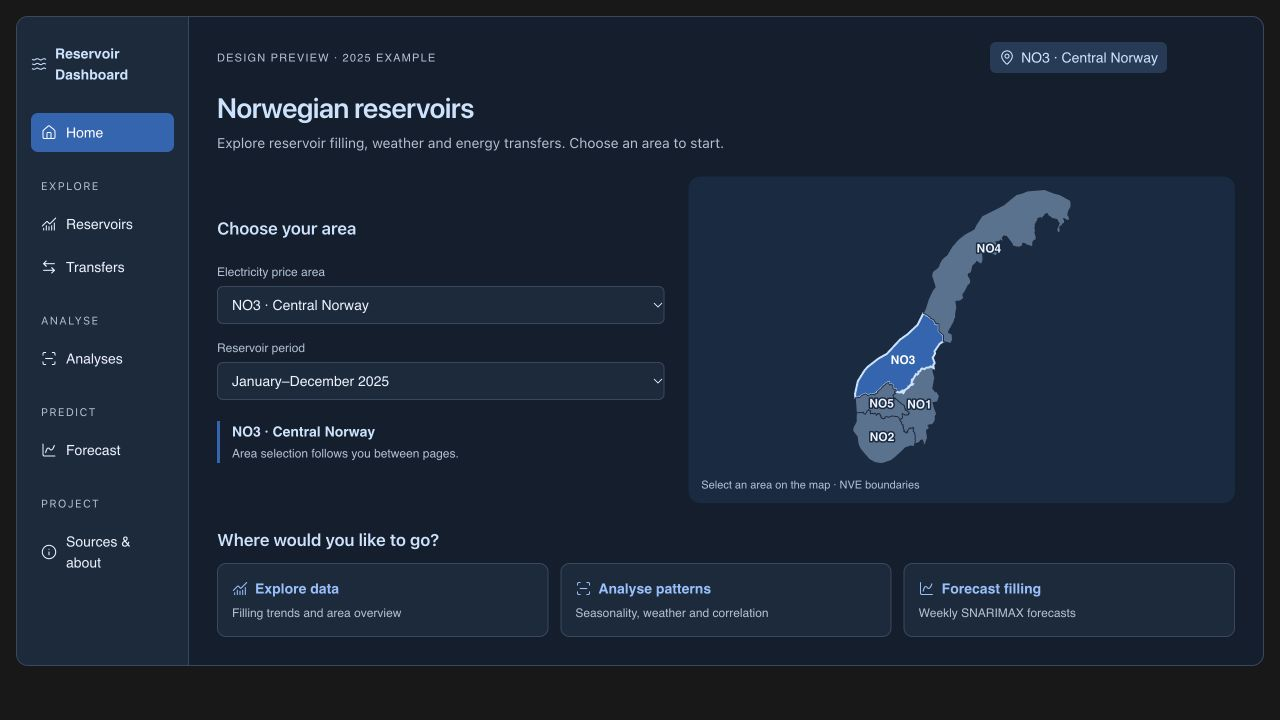

Home places the area selector beside the map and offers direct routes to data, analyses and forecasting. Clicking an electricity price area updates the selector and selected outline. The same area is retained when navigating to reservoir or forecast views. The preview uses NO3 and the 2025 reservoir period.

### 4.2 Proposed navigation

| Group | Page | Content |
| --- | --- | --- |
| Home | Home | Map, shared area selection, reservoir period and task buttons. |
| Explore | Reservoirs | Combine Data Table and Data Plot: interactive measurement plots, area overview with `LineChartColumn` trends, and detailed data. |
| Explore | Transfers | Existing ENTSO-E import/export analysis and table, with local connection and period controls. |
| Analyse | Analyses | Separate tabs for reservoir STL/spectrogram, weather SATV/LOF, and weather–reservoir sliding-window correlation. |
| Predict | Forecast | SNARIMAX inputs, training window, horizon, weather scenario, dynamic forecast and animation. |
| Project | Sources & about | Combine Reservoir API and About: source definitions, downloads, caching, time alignment, coverage and limitations. |

The final map must also support national and VASS selections. Verify that geographical boundaries match the reservoir and weather region definitions before adding those layers. Map colour controls will select an available aggregate such as filling or weather and a time; a missing measure must remain visibly unavailable. The current project sources do not supply electricity prices, so price colouring requires a verified price source before it can be offered.

### 4.3 Forecast page

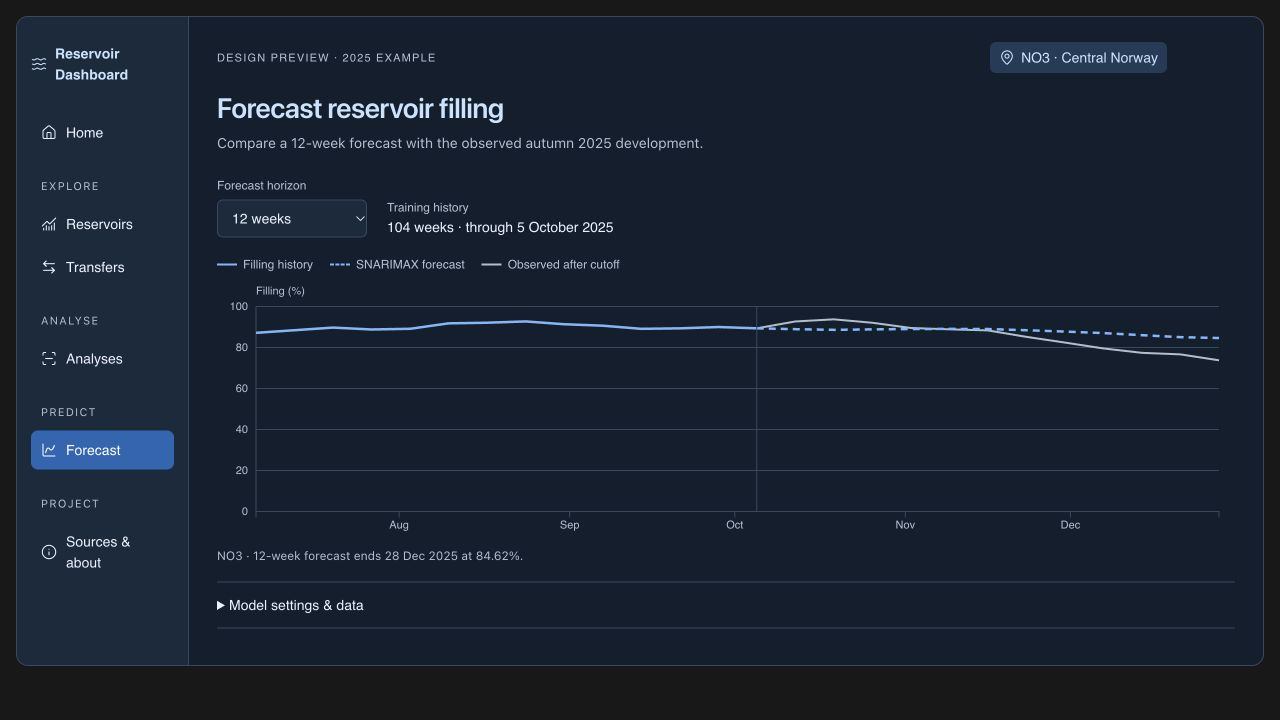

Keep the selected area visible and place the horizon near the forecast. Put detailed model settings below the plot. Start with NO3, 104 training weeks, 12 forecast weeks and filling history, using p=1, d=1, q=1, m=52, sp=1, sd=0 and sq=0. The final interface will expose the model orders, training bounds and input selection. Precipitation remains an optional historical-week-means scenario, with its two-observation basis and limitations explained. Add forecast animation during implementation; it is not represented by this still image.

### 4.4 Shared and page-specific controls

| Control | Scope and proposed behaviour |
| --- | --- |
| Area type and area number | Shared through `session_state`; keep a separate area choice per EL/NO/VASS type. A map click and selector change update the same stored choice. |
| Reservoir display period | Shared by the map's reservoir view and Reservoirs page. Keep its meaning separate from model training bounds and the complete weather-year selection. |
| Map time and colour measure | Local to the map, retained on returning to Home. These do not silently change forecast training dates. |
| Reservoir measurement | Local to the reservoir view. |
| Analysis period and weather year | Local to the relevant analysis; clearly label their date coverage. |
| SATV and LOF weather property | Local to each analysis, with temperature as the SATV starting choice. |
| Correlation variables, lag and window | Local to the correlation tab; display the lag convention and units beside the controls. |
| Forecast training dates, horizon, orders and selected sources | Local to Forecast, retained through `session_state`; region follows the shared area. Recompute on an explicit forecast action. |
| Transfer connection and period | Local to Transfers. |

Use interactive plots throughout the final app, consistent blue styling, clear loading progress and concise missing-data messages. Reuse cached reads and saved weather data. Keep unavailable weather or geographical combinations visible through a specific message rather than silently substituting another area.

Implement the shared navigation, theme and area state first, then complete the geographical layers and map controls, migrate the analyses to interactive plots, and add the forecast interface and animation. Check that page navigation preserves the intended controls and that every figure labels its area, time range and units.